# Lab Assignment 9 — Vision-based Cognitive Systems (Landing AI)
**Course:** UCS420 Cognitive Computing &nbsp;|&nbsp; **Name:** Kavay Khurana &nbsp;|&nbsp; **Roll No.:** 1024170154


## 0. Setup

In [56]:
import sys, subprocess, importlib.util, os

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    missing = [p for p in pkgs if importlib.util.find_spec(p.split("==")[0].replace("-", "_").split("[")[0]) is None]
    if missing:
        print("Installing:", missing)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)

# Core requirements (safe everywhere)
pip_install("rapidfuzz", "pytesseract", "kagglehub")
# Optional extras — the notebook works without them
for opt in ["easyocr", "gTTS", "google-genai"]:
    spec_name = {"gTTS": "gtts", "google-genai": "google.genai"}.get(opt, opt)
    try:
        found = importlib.util.find_spec(spec_name) is not None
    except ModuleNotFoundError:
        found = False
    if not found and IN_COLAB:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", opt], check=False)

if IN_COLAB:
    # Tesseract binary for pytesseract
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True, check=False)
print("Colab:", IN_COLAB)

Colab: False


In [57]:
import re, json, math, random, shutil, glob, time, warnings, textwrap, calendar
import datetime as dt
from pathlib import Path
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path(os.environ.get("LAB9_ROOT", ".")).resolve()
DATA = ROOT / "data"; OUT = ROOT / "outputs"
DATA.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
TODAY = dt.date.today()

GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")

def show(img, title=None, size=6):
    """Display a BGR/gray numpy image or PIL image."""
    if isinstance(img, Image.Image):
        img = np.array(img)
    elif img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(size, size * img.shape[0] / img.shape[1]))
    plt.imshow(img, cmap="gray" if img.ndim == 2 else None); plt.axis("off")
    if title: plt.title(title)
    plt.show()

def llm_generate(prompt):
    """Optional Gemini call. Returns None when no key / SDK / network — callers fall back to rules."""
    key = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
    if not key:
        return None
    try:
        from google import genai
        client = genai.Client(api_key=key)
        resp = client.models.generate_content(model=GEMINI_MODEL, contents=prompt)
        text = (resp.text or "").strip()
        return text or None
    except Exception as e:
        print(f"[LLM unavailable: {type(e).__name__}] falling back to rule-based response")
        return None

def speak(text, filename):
    """Text-to-speech via gTTS (needs internet). Returns path or None."""
    try:
        from gtts import gTTS
        path = OUT / filename
        gTTS(text=text, lang="en", tld="co.in").save(str(path))
        return path
    except Exception as e:
        print(f"[TTS skipped: {type(e).__name__}] — install gTTS and run with internet for audio output")
        return None

print("Root:", ROOT, "| Today:", TODAY, "| OpenCV", cv2.__version__)

Root: /Users/kavaykhurana/Desktop/cognitive_computing_UCS420/assignment-9 | Today: 2026-10-31 | OpenCV 5.0.0


---
# PART A — Cognitive Assistant for Reading Medicine Bottle Labels

**Problem.** Elderly and visually impaired users struggle to read small, curved, glossy print on medicine bottles: drug name, strength, dosage, expiry. Reading the text is only half the job — the assistant has to *understand* it: is it expired, is the dose safe, does it clash with something else I take?

**Pipeline**

| Stage | Cognitive function | Implementation |
|---|---|---|
| 1. Capture quality check | Metacognition | Laplacian variance (blur), exposure → retake advice before OCR; missing-field advice after OCR |
| 2. Label localisation | Attention | Canny + contour → largest quadrilateral → perspective warp |
| 3. Image enhancement | Perception | Upscale, CLAHE, denoise, deskew, adaptive/Otsu binarisation (several variants) |
| 4. OCR | Recognition | Tesseract (always) + EasyOCR (if installed) on every variant |
| 5. Entity extraction | Language understanding | Fuzzy lexicon matching weighted by font size (salience), regex for strength / dates / batch / dosage |
| 6. Field voting | Evidence fusion | Confidence-weighted vote across OCR variants |
| 7. Reasoning | Knowledge + rules | Drug KB (generic, class, use, max daily dose), expiry logic, dose arithmetic |
| 8. Memory | Working memory | Medicine cabinet: duplicate ingredient, same-class and known-interaction alerts |
| 9. Interaction | Communication | Spoken summary (gTTS), intent-based Q&A, optional Gemini for open questions |

**Dataset.**
1. **Synthetic labelled set (built in this notebook)** — realistic bottle labels rendered with known ground truth, then degraded with bottle curvature, perspective, glare, blur, noise and JPEG artefacts at three severity levels. Ground truth makes field-level accuracy measurable, which real scraped photos cannot give.
2. **Real photos from the internet** — the Roboflow Universe *BottleLabels* dataset (free API key) and/or any bottle photos dropped into `data/real_labels/`.

## A1. Drug knowledge base
Indian brand → generic composition, therapeutic class, use, and adult maximum daily dose where a single well-established figure exists (`None` = dose is individualised, so no automatic check). Interaction pairs are the common, well-documented ones.

In [58]:
GENERICS = {
    "paracetamol":   {"class": "analgesic/antipyretic", "use": "fever and mild-to-moderate pain", "max_daily_mg": 4000},
    "ibuprofen":     {"class": "NSAID", "use": "pain, inflammation and fever", "max_daily_mg": 2400},
    "aspirin":       {"class": "NSAID/antiplatelet", "use": "low dose: prevents blood clots; high dose: pain", "max_daily_mg": 4000},
    "cetirizine":    {"class": "antihistamine", "use": "allergy, sneezing, itching", "max_daily_mg": 10},
    "levocetirizine":{"class": "antihistamine", "use": "allergic rhinitis and urticaria", "max_daily_mg": 5},
    "fexofenadine":  {"class": "antihistamine", "use": "allergic rhinitis and urticaria", "max_daily_mg": 180},
    "montelukast":   {"class": "leukotriene antagonist", "use": "asthma and allergic rhinitis", "max_daily_mg": 10},
    "pantoprazole":  {"class": "proton pump inhibitor", "use": "acidity, GERD, ulcers", "max_daily_mg": None},
    "omeprazole":    {"class": "proton pump inhibitor", "use": "acidity, GERD, ulcers", "max_daily_mg": None},
    "metformin":     {"class": "antidiabetic (biguanide)", "use": "type 2 diabetes", "max_daily_mg": 2550},
    "atorvastatin":  {"class": "statin", "use": "high cholesterol", "max_daily_mg": 80},
    "amlodipine":    {"class": "calcium channel blocker", "use": "high blood pressure, angina", "max_daily_mg": 10},
    "telmisartan":   {"class": "ARB antihypertensive", "use": "high blood pressure", "max_daily_mg": 80},
    "azithromycin":  {"class": "macrolide antibiotic", "use": "bacterial infections", "max_daily_mg": None},
    "amoxicillin":   {"class": "penicillin antibiotic", "use": "bacterial infections", "max_daily_mg": None},
    "levothyroxine": {"class": "thyroid hormone", "use": "hypothyroidism", "max_daily_mg": None},
}

# brand -> {"generics": [(generic, strength, unit)], "form": ..., "dose": label instruction, "rx": schedule H?}
BRANDS = {
    "Dolo 650":      {"generics": [("paracetamol", 650, "mg")], "form": "tablet", "dose": "1 tablet every 6 hours. Do not exceed 4 tablets in 24 hours.", "rx": False},
    "Crocin Advance":{"generics": [("paracetamol", 500, "mg")], "form": "tablet", "dose": "1 tablet every 6 hours. Do not exceed 8 tablets in 24 hours.", "rx": False},
    "Combiflam":     {"generics": [("ibuprofen", 400, "mg"), ("paracetamol", 325, "mg")], "form": "tablet", "dose": "1 tablet three times a day after food.", "rx": False},
    "Brufen 400":    {"generics": [("ibuprofen", 400, "mg")], "form": "tablet", "dose": "1 tablet three times a day after meals.", "rx": True},
    "Cetzine":       {"generics": [("cetirizine", 10, "mg")], "form": "tablet", "dose": "1 tablet once daily at bedtime.", "rx": False},
    "Allegra 120":   {"generics": [("fexofenadine", 120, "mg")], "form": "tablet", "dose": "1 tablet once daily.", "rx": True},
    "Pan 40":        {"generics": [("pantoprazole", 40, "mg")], "form": "tablet", "dose": "1 tablet once daily before breakfast.", "rx": True},
    "Glycomet 500":  {"generics": [("metformin", 500, "mg")], "form": "tablet", "dose": "1 tablet twice daily with meals.", "rx": True},
    "Ecosprin 75":   {"generics": [("aspirin", 75, "mg")], "form": "tablet", "dose": "1 tablet once daily after lunch.", "rx": True},
    "Azithral 500":  {"generics": [("azithromycin", 500, "mg")], "form": "tablet", "dose": "1 tablet once daily for 3 days.", "rx": True},
    "Mox 500":       {"generics": [("amoxicillin", 500, "mg")], "form": "capsule", "dose": "1 capsule three times a day.", "rx": True},
    "Atorva 10":     {"generics": [("atorvastatin", 10, "mg")], "form": "tablet", "dose": "1 tablet once daily at night.", "rx": True},
    "Amlong 5":      {"generics": [("amlodipine", 5, "mg")], "form": "tablet", "dose": "1 tablet once daily.", "rx": True},
    "Thyronorm 50":  {"generics": [("levothyroxine", 50, "mcg")], "form": "tablet", "dose": "1 tablet once daily on an empty stomach.", "rx": True},
    "Montair LC":    {"generics": [("montelukast", 10, "mg"), ("levocetirizine", 5, "mg")], "form": "tablet", "dose": "1 tablet once daily at night.", "rx": True},
    "Telma 40":      {"generics": [("telmisartan", 40, "mg")], "form": "tablet", "dose": "1 tablet once daily.", "rx": True},
    "Omez 20":       {"generics": [("omeprazole", 20, "mg")], "form": "capsule", "dose": "1 capsule once daily before breakfast.", "rx": True},
}

INTERACTIONS = {
    frozenset({"ibuprofen", "aspirin"}): "Ibuprofen can blunt aspirin's antiplatelet effect and both raise stomach-bleeding risk.",
    frozenset({"ibuprofen", "telmisartan"}): "NSAIDs can reduce the blood-pressure-lowering effect of ARBs and stress the kidneys.",
    frozenset({"aspirin", "telmisartan"}): "High-dose aspirin can reduce ARB effect; low-dose is usually fine — confirm with a doctor.",
    frozenset({"levothyroxine", "pantoprazole"}): "PPIs can reduce levothyroxine absorption — separate doses and monitor thyroid levels.",
    frozenset({"levothyroxine", "omeprazole"}): "PPIs can reduce levothyroxine absorption — separate doses and monitor thyroid levels.",
}

BRAND_KEYS = {b.split()[0].lower(): b for b in BRANDS}          # 'dolo' -> 'Dolo 650'
print(f"KB: {len(BRANDS)} brands, {len(GENERICS)} generics, {len(INTERACTIONS)} interaction rules")
pd.DataFrame([{"brand": b, "composition": " + ".join(f"{g} {s} {u}" for g, s, u in v["generics"]),
               "form": v["form"], "schedule H": v["rx"]} for b, v in BRANDS.items()])

KB: 17 brands, 16 generics, 5 interaction rules


,brand,composition,form,schedule H
0,Dolo 650,paracetamol 650 mg,tablet,False
1,Crocin Advance,paracetamol 500 mg,tablet,False
2,Combiflam,ibuprofen 400 mg + paracetamol 325 mg,tablet,False
3,Brufen 400,ibuprofen 400 mg,tablet,True
4,Cetzine,cetirizine 10 mg,tablet,False
5,Allegra 120,fexofenadine 120 mg,tablet,True
6,Pan 40,pantoprazole 40 mg,tablet,True
7,Glycomet 500,metformin 500 mg,tablet,True
8,Ecosprin 75,aspirin 75 mg,tablet,True
9,Azithral 500,azithromycin 500 mg,tablet,True


## A2. Dataset
### A2.1 Synthetic medicine-label generator (with ground truth)
Each label carries the same fields a real Indian label does — brand, composition, dosage, batch number, Mfg/Exp dates, manufacturer, storage/warning lines and the Schedule H notice. Date and batch formats are randomised across the styles used by Indian manufacturers (`02/2027`, `FEB.2027`, `02/27`). About 25% of labels are already expired so the reasoning layer has something to catch.

In [59]:
FONT_REG = font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans"))
FONT_BOLD = font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold"))
MANUFACTURERS = ["Ventara Pharma Ltd., Baddi (H.P.)", "Sunveda Remedies Pvt. Ltd., Sikkim",
                 "Nirmal Healthcare Ltd., Ahmedabad", "Kaveri Life Sciences, Hyderabad",
                 "Indus Generics Ltd., Daman"]
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]

def add_months(y, m, k):
    t = y * 12 + (m - 1) + k
    return t // 12, t % 12 + 1

def fmt_date(y, m, style):
    return {0: f"{m:02d}/{y}", 1: f"{MONTHS[m-1]}.{y}", 2: f"{m:02d}/{y % 100:02d}"}[style]

def wrap_text(draw, text, font, max_w):
    words, lines, cur = text.split(), [], ""
    for w in words:
        trial = (cur + " " + w).strip()
        if draw.textlength(trial, font=font) <= max_w:
            cur = trial
        else:
            lines.append(cur); cur = w
    if cur: lines.append(cur)
    return lines

def render_label(brand, rng):
    info = BRANDS[brand]
    W, H = 1100, 700
    pick = lambda opts: opts[int(rng.integers(len(opts)))]
    bg = pick([(255, 255, 255), (246, 250, 255), (255, 251, 240), (244, 255, 246)])
    accent = pick([(196, 30, 58), (20, 70, 160), (0, 120, 90), (120, 40, 140), (210, 100, 0)])
    img = Image.new("RGB", (W, H), bg); d = ImageDraw.Draw(img)
    f = lambda s, b=False: ImageFont.truetype(FONT_BOLD if b else FONT_REG, s)
    d.rectangle([0, 0, W, 26], fill=accent); d.rectangle([0, H - 26, W, H], fill=accent)

    # fields
    today_idx = TODAY.year * 12 + TODAY.month - 1
    expired = rng.random() < 0.25
    shelf = int(rng.choice([24, 36]))
    if expired:
        exp_idx = today_idx - int(rng.integers(1, 18))
    else:
        exp_idx = today_idx + int(rng.integers(3, 30))
    ey, em = exp_idx // 12, exp_idx % 12 + 1
    my, mm = add_months(ey, em, -shelf)
    style = int(rng.integers(0, 3))
    prefix = pick(["B.No.", "Batch No.", "Lot No."])
    batch = "".join(rng.choice(list("ABCDEFGHJKLMNPRSTUVWXYZ"), 2)) + str(my % 100).zfill(2) + \
            "".join(rng.choice(list("ABCDEFGHJKLMNPRSTUVWXYZ0123456789"), 1)) + str(int(rng.integers(100, 999)))
    manu = pick(MANUFACTURERS)

    y = 48
    d.text((40, y), brand, font=f(76, True), fill=accent); y += 98
    comp = " + ".join(f"{g.title()} {s} {u}" for g, s, u in info["generics"])
    d.text((40, y), f"{comp} {info['form'].title()}s IP", font=f(32, True), fill=(30, 30, 30)); y += 50
    each = "Each uncoated tablet contains:" if info["form"] == "tablet" else "Each capsule contains:"
    d.text((40, y), each + " " + ", ".join(f"{g.title()} IP {s} {u}" for g, s, u in info["generics"]),
           font=f(22), fill=(40, 40, 40)); y += 40
    for line in wrap_text(d, "Dosage: " + info["dose"] + " Or as directed by the physician.", f(26), W - 80):
        d.text((40, y), line, font=f(26), fill=(20, 20, 20)); y += 34
    y += 8
    d.text((40, y), f"{prefix}: {batch}", font=f(28, True), fill=(10, 10, 10))
    d.text((560, y), f"Mfg. Date: {fmt_date(my, mm, style)}", font=f(28, True), fill=(10, 10, 10)); y += 42
    d.text((560, y), f"Exp. Date: {fmt_date(ey, em, style)}", font=f(28, True), fill=(10, 10, 10))
    d.text((40, y), "Store below 30°C. Protect from light.", font=f(22), fill=(50, 50, 50)); y += 46
    d.text((40, y), "Keep out of reach of children.", font=f(22), fill=(50, 50, 50)); y += 34
    if info["rx"]:
        for line in wrap_text(d, "SCHEDULE H PRESCRIPTION DRUG - CAUTION: Not to be sold by retail without the "
                              "prescription of a Registered Medical Practitioner.", f(20, True), W - 80):
            d.text((40, y), line, font=f(20, True), fill=(160, 0, 0)); y += 26
    d.text((40, H - 70), "Mfd. by: " + manu, font=f(22), fill=(40, 40, 40))

    gt = {"brand": brand, "strength": f"{info['generics'][0][1]} {info['generics'][0][2]}",
          "batch": batch, "expiry": f"{em:02d}/{ey}", "mfg": f"{mm:02d}/{my}", "expired": expired}
    return cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR), gt

### A2.2 Photographic degradations — making it look like a phone photo of a bottle

In [60]:
def cylinder_warp(img, half_angle_deg):
    """Wrap a flat label around a cylinder: compress towards the edges and add edge shading."""
    h, w = img.shape[:2]
    a = math.radians(half_angle_deg)
    u = np.linspace(-1, 1, w)
    phi = np.arcsin(np.clip(u * math.sin(a), -1, 1))
    src_x = ((phi / a) + 1) / 2 * (w - 1)
    map_x = np.tile(src_x.astype(np.float32), (h, 1))
    map_y = np.tile(np.arange(h, dtype=np.float32)[:, None], (1, w))
    out = cv2.remap(img, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    shade = (np.cos(phi) ** 0.6)[None, :, None]
    return np.clip(out * shade, 0, 255).astype(np.uint8)

def photo_augment(label, severity, rng):
    p = {"clean": dict(curv=8, rot=1.5, persp=0.01, blur=0, noise=2, glare=0.0, jpeg=95),
         "mild":  dict(curv=28, rot=4, persp=0.03, blur=1, noise=6, glare=0.35, jpeg=75),
         "hard":  dict(curv=45, rot=8, persp=0.06, blur=2, noise=12, glare=0.7, jpeg=55)}[severity]
    img = cylinder_warp(label, p["curv"] * rng.uniform(0.6, 1.0))
    h, w = img.shape[:2]
    # place on a background "table"
    pad = 120
    H, W = h + 2 * pad, w + 2 * pad
    base = np.array(rng.integers(40, 140, 3), dtype=np.float32)
    grad = np.linspace(0.75, 1.15, W)[None, :, None] * np.linspace(0.85, 1.1, H)[:, None, None]
    canvas = np.clip(base * grad + rng.normal(0, 6, (H, W, 3)), 0, 255).astype(np.uint8)
    # perspective
    j = p["persp"]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32([[pad + rng.uniform(-j, j) * w, pad + rng.uniform(-j, j) * h],
                      [pad + w + rng.uniform(-j, j) * w, pad + rng.uniform(-j, j) * h],
                      [pad + w + rng.uniform(-j, j) * w, pad + h + rng.uniform(-j, j) * h],
                      [pad + rng.uniform(-j, j) * w, pad + h + rng.uniform(-j, j) * h]])
    M = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(img, M, (W, H))
    mask = cv2.warpPerspective(np.full((h, w), 255, np.uint8), M, (W, H))
    canvas[mask > 0] = warped[mask > 0]
    # rotation
    R = cv2.getRotationMatrix2D((W / 2, H / 2), rng.uniform(-p["rot"], p["rot"]), 1.0)
    canvas = cv2.warpAffine(canvas, R, (W, H), borderMode=cv2.BORDER_REFLECT)
    # glare: bright elliptical specular highlight
    if rng.random() < p["glare"]:
        g = np.zeros((H, W), np.float32)
        cx, cy = int(rng.uniform(0.3, 0.7) * W), int(rng.uniform(0.3, 0.7) * H)
        cv2.ellipse(g, (cx, cy), (int(W * 0.05), int(H * 0.28)), rng.uniform(-15, 15), 0, 360, 1.0, -1)
        g = cv2.GaussianBlur(g, (0, 0), 25) * rng.uniform(0.5, 0.85)
        canvas = np.clip(canvas + g[..., None] * 255, 0, 255).astype(np.uint8)
    if p["blur"]:
        canvas = cv2.GaussianBlur(canvas, (0, 0), p["blur"] * rng.uniform(0.6, 1.0))
    canvas = np.clip(canvas + rng.normal(0, p["noise"], canvas.shape), 0, 255).astype(np.uint8)
    ok, enc = cv2.imencode(".jpg", canvas, [cv2.IMWRITE_JPEG_QUALITY, p["jpeg"]])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR)

def build_synthetic_dataset(n_per_severity=20, seed=SEED):
    rng = np.random.default_rng(seed)
    root = DATA / "synthetic_labels"
    if root.exists(): shutil.rmtree(root)
    rows = []
    brands = list(BRANDS)
    for sev in ["clean", "mild", "hard"]:
        (root / sev).mkdir(parents=True, exist_ok=True)
        for i in range(n_per_severity):
            brand = brands[(i + {"clean": 0, "mild": 5, "hard": 11}[sev]) % len(brands)]
            label, gt = render_label(brand, rng)
            photo = photo_augment(label, sev, rng)
            path = root / sev / f"{sev}_{i:03d}.jpg"
            cv2.imwrite(str(path), photo)
            rows.append({"path": str(path), "severity": sev, **gt})
    df = pd.DataFrame(rows)
    df.to_csv(root / "ground_truth.csv", index=False)
    return df

N_PER_SEVERITY = int(os.environ.get("LAB9_N_PER_SEVERITY", 20))
gt_df = build_synthetic_dataset(N_PER_SEVERITY)
print(gt_df.severity.value_counts().to_dict(), "| expired labels:", int(gt_df.expired.sum()))
gt_df.head()

{'clean': 20, 'mild': 20, 'hard': 20} | expired labels: 19


,path,severity,brand,strength,batch,expiry,mfg,expired
0,/Users/kavaykhurana/Desktop/cognitive_computin...,clean,Dolo 650,650 mg,EC26U977,12/2028,12/2026,False
1,/Users/kavaykhurana/Desktop/cognitive_computin...,clean,Crocin Advance,500 mg,SN269666,08/2028,08/2026,False
2,/Users/kavaykhurana/Desktop/cognitive_computin...,clean,Combiflam,400 mg,ZV23N648,05/2025,05/2023,True
3,/Users/kavaykhurana/Desktop/cognitive_computin...,clean,Brufen 400,400 mg,RL23J278,05/2025,05/2023,True
4,/Users/kavaykhurana/Desktop/cognitive_computin...,clean,Cetzine,10 mg,KY253982,06/2028,06/2025,False


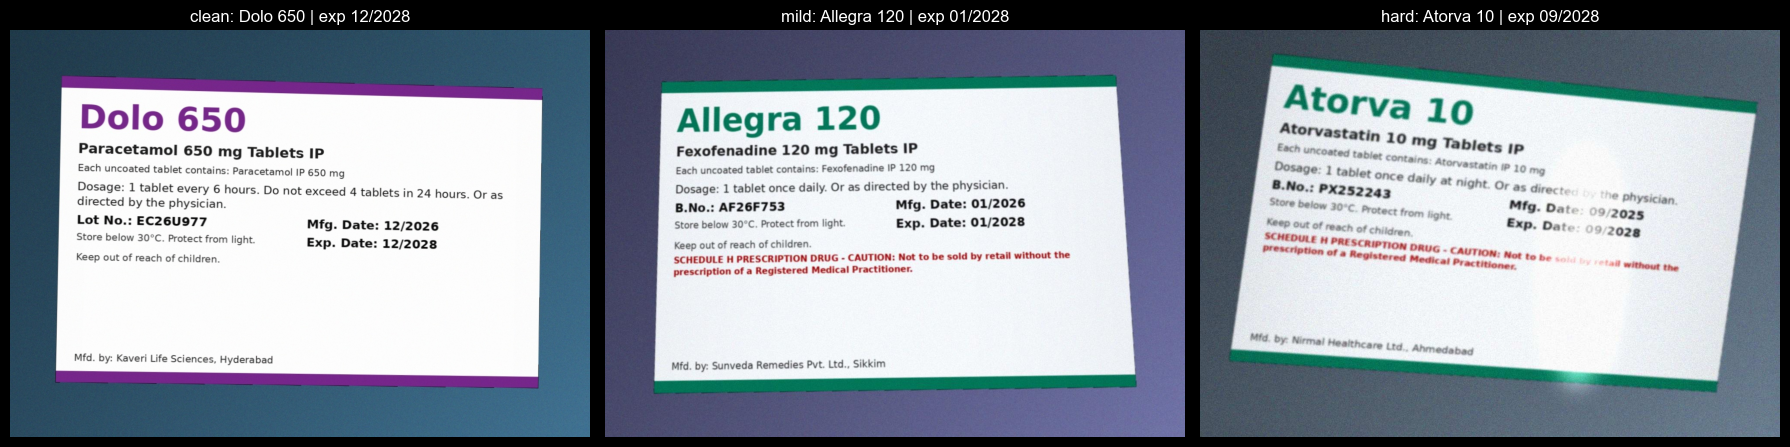

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, sev in zip(axes, ["clean", "mild", "hard"]):
    r = gt_df[gt_df.severity == sev].iloc[0]
    ax.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{sev}: {r.brand} | exp {r.expiry}")
plt.tight_layout(); plt.show()

### A2.3 Real bottle photos from the internet (optional)
Roboflow Universe hosts public bottle-label datasets, e.g. **BottleLabels** — https://universe.roboflow.com/koo-a3lwf/bottlelabels. Create a free Roboflow account, copy your API key, and set `ROBOFLOW_API_KEY`. Any `.jpg/.png` you put in `data/real_labels/` (your own phone photos work best) is also picked up in section A8.

In [62]:
REAL_DIR = DATA / "real_labels"; REAL_DIR.mkdir(parents=True, exist_ok=True)

def download_roboflow(workspace="koo-a3lwf", project="bottlelabels", max_images=25):
    key = os.environ.get("ROBOFLOW_API_KEY")
    if not key:
        print("ROBOFLOW_API_KEY not set — skipping Roboflow download (synthetic set is used for evaluation).")
        return []
    try:
        pip_install("roboflow")
        from roboflow import Roboflow
        proj = Roboflow(api_key=key).workspace(workspace).project(project)
        versions = proj.versions()
        latest = max(versions, key=lambda v: int(str(v.version).split("/")[-1]))
        ds = latest.download("folder", location=str(DATA / "roboflow_bottlelabels"), overwrite=True)
        imgs = sorted(p for p in Path(ds.location).rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
        for p in imgs[:max_images]:
            shutil.copy(p, REAL_DIR / p.name)
        print(f"Copied {min(len(imgs), max_images)} Roboflow images into {REAL_DIR}")
        return imgs[:max_images]
    except Exception as e:
        print(f"Roboflow download failed ({type(e).__name__}: {e}). Put photos in {REAL_DIR} manually.")
        return []

_ = download_roboflow()

if IN_COLAB:
    print("Colab: run `from google.colab import files; files.upload()` and move files into", REAL_DIR)

ROBOFLOW_API_KEY not set — skipping Roboflow download (synthetic set is used for evaluation).


## A3. Perception — capture quality check, label localisation, enhancement

Quality: (True, [], {'sharpness': np.float64(226.2), 'overexposed_ratio': 0.025, 'brightness': 170.0})
Label localised: True


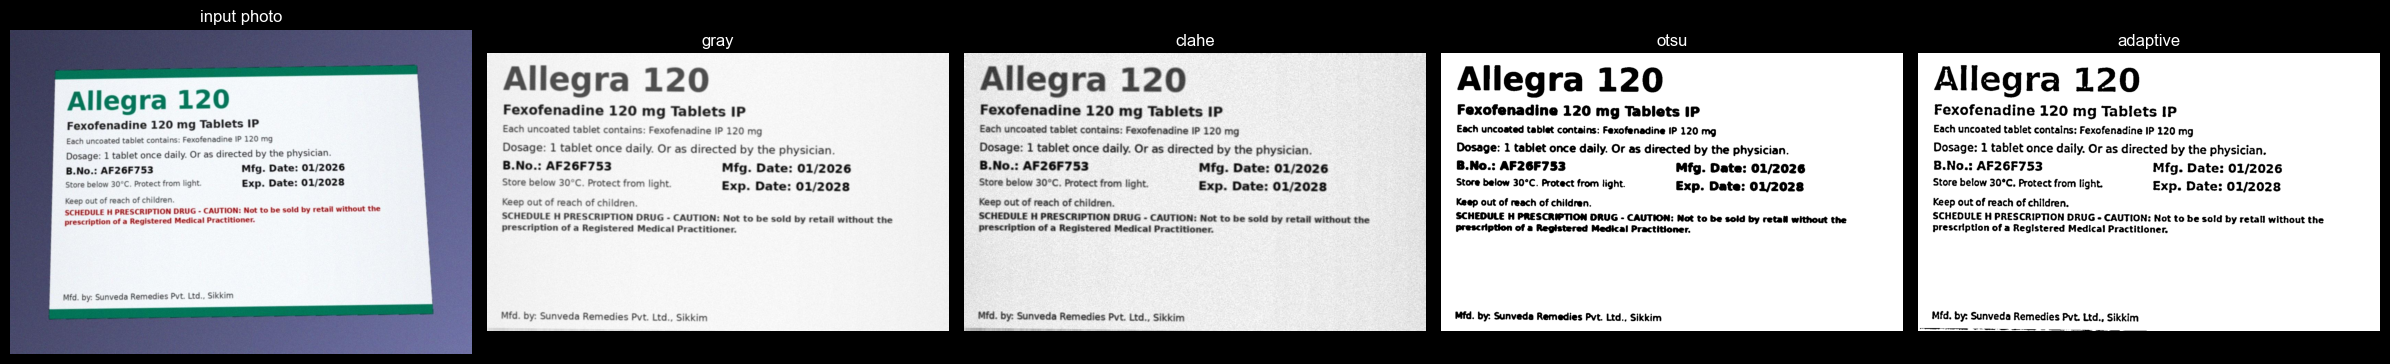

In [63]:
def assess_quality(img):
    """Pre-OCR perception check -> (ok, issues, metrics).
    Sharpness = variance of the Laplacian after a 3x3 median filter (the filter stops sensor noise from
    masquerading as detail). Threshold 100 was calibrated on the synthetic set: clean ~500, mild ~220, hard ~65."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    scale = 1000 / max(g.shape)
    g = cv2.resize(g, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    sharp = cv2.Laplacian(cv2.medianBlur(g, 3), cv2.CV_64F).var()
    blown = float((g >= 250).mean())
    bright = float(g.mean())
    issues = []
    if sharp < 100: issues.append("Image looks blurry — hold the bottle steady and tap to focus.")
    if blown > 0.6: issues.append("Image is overexposed — move away from direct light.")
    if bright < 60: issues.append("Image is too dark — move to better light.")
    return len(issues) == 0, issues, {"sharpness": round(sharp, 1), "overexposed_ratio": round(blown, 3), "brightness": round(bright, 1)}

def order_corners(pts):
    pts = pts.reshape(4, 2).astype(np.float32)
    s, d = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])

def localize_label(img):
    """Attention: find the label as the largest bright quadrilateral; perspective-correct it.
    Falls back to the full frame when no confident quadrilateral exists."""
    h, w = img.shape[:2]
    scale = 800 / max(h, w)
    small = cv2.resize(img, None, fx=scale, fy=scale)
    g = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    _, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    best = None
    for c in sorted(cnts, key=cv2.contourArea, reverse=True)[:5]:
        area = cv2.contourArea(c)
        if area < 0.2 * small.shape[0] * small.shape[1] or area > 0.98 * small.shape[0] * small.shape[1]:
            continue
        approx = cv2.approxPolyDP(c, 0.02 * cv2.arcLength(c, True), True)
        if len(approx) == 4:
            best = approx; break
        rect = cv2.boxPoints(cv2.minAreaRect(c))
        if area / (cv2.contourArea(rect) + 1e-6) > 0.85:
            best = rect; break
    if best is None:
        return img, False
    quad = order_corners(best) / scale
    wA = np.linalg.norm(quad[1] - quad[0]); wB = np.linalg.norm(quad[2] - quad[3])
    hA = np.linalg.norm(quad[3] - quad[0]); hB = np.linalg.norm(quad[2] - quad[1])
    W, H = int(max(wA, wB)), int(max(hA, hB))
    M = cv2.getPerspectiveTransform(quad, np.float32([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]]))
    return cv2.warpPerspective(img, M, (W, H)), True

def deskew(gray):
    """Estimate dominant text angle from the minimum-area rectangle of dark pixels; only small corrections."""
    inv = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    coords = np.column_stack(np.where(inv > 0))
    if len(coords) < 500:
        return gray
    angle = cv2.minAreaRect(coords[:, ::-1].astype(np.float32))[-1]
    if angle > 45: angle -= 90
    if abs(angle) < 0.5 or abs(angle) > 10:
        return gray
    h, w = gray.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def enhance_variants(img):
    """Several enhanced views of the same label; OCR runs on each and fields are voted."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if g.shape[1] < 1600:
        f = 1600 / g.shape[1]
        g = cv2.resize(g, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    g = deskew(g)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    den = cv2.fastNlMeansDenoising(clahe, h=10)
    otsu = cv2.threshold(cv2.GaussianBlur(den, (3, 3), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    adapt = cv2.adaptiveThreshold(den, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 41, 15)
    return {"gray": g, "clahe": clahe, "otsu": otsu, "adaptive": adapt}

sample = cv2.imread(gt_df[gt_df.severity == "mild"].iloc[0].path)
print("Quality:", assess_quality(sample))
crop, found = localize_label(sample)
print("Label localised:", found)
vars_ = enhance_variants(crop)
fig, axes = plt.subplots(1, 5, figsize=(24, 4))
axes[0].imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB)); axes[0].set_title("input photo")
for ax, (k, v) in zip(axes[1:], vars_.items()):
    ax.imshow(v, cmap="gray"); ax.set_title(k)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## A4. Recognition — OCR engines
Tesseract is always available. EasyOCR (deep CRAFT detector + CRNN recogniser) is used too when installed — it is markedly better on curved and low-contrast print and runs fast on a Colab GPU. Every engine returns lines as `{text, conf (0–1), height}`; line height feeds the salience weighting used to pick the brand name.

In [64]:
import pytesseract

def tesseract_available():
    try:
        pytesseract.get_tesseract_version(); return True
    except Exception:
        return False

HAS_TESS = tesseract_available()
_easy_reader = None
def get_easyocr():
    global _easy_reader
    if _easy_reader is None:
        try:
            import easyocr, torch
            _easy_reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)
        except Exception as e:
            print(f"[EasyOCR unavailable: {type(e).__name__}]")
            _easy_reader = False
    return _easy_reader or None

USE_EASYOCR = os.environ.get("LAB9_EASYOCR", "1") == "1"
print("Tesseract:", HAS_TESS, "| EasyOCR enabled:", USE_EASYOCR and get_easyocr() is not None)
if not HAS_TESS and not (USE_EASYOCR and get_easyocr()):
    raise RuntimeError("No OCR engine. Install Tesseract (apt-get install tesseract-ocr) or `pip install easyocr`.")

def ocr_tesseract(img, psm=6):
    df = pytesseract.image_to_data(img, config=f"--oem 3 --psm {psm}", output_type=pytesseract.Output.DATAFRAME)
    df = df[(df.conf > 0) & df.text.notna()]
    df = df[df.text.astype(str).str.strip() != ""]
    lines = []
    for _, grp in df.groupby(["block_num", "par_num", "line_num"], sort=True):
        lines.append({"text": " ".join(grp.text.astype(str)), "conf": float(grp.conf.mean()) / 100,
                      "height": float(grp.height.median()), "y": float(grp.top.min())})
    return sorted(lines, key=lambda l: l["y"])

def ocr_easyocr(img):
    reader = get_easyocr()
    if reader is None:
        return []
    res = reader.readtext(img, detail=1, paragraph=False)
    items = [{"text": t, "conf": float(c), "height": float(max(p[1] for p in b) - min(p[1] for p in b)),
              "y": float(np.mean([p[1] for p in b])), "x": float(min(p[0] for p in b))} for b, t, c in res]
    # group boxes into lines by vertical centre
    items.sort(key=lambda r: r["y"])
    lines, cur = [], []
    for it in items:
        if cur and abs(it["y"] - np.mean([c["y"] for c in cur])) > 0.5 * np.median([c["height"] for c in cur]):
            lines.append(cur); cur = []
        cur.append(it)
    if cur: lines.append(cur)
    out = []
    for ln in lines:
        ln.sort(key=lambda r: r["x"])
        out.append({"text": " ".join(r["text"] for r in ln), "conf": float(np.mean([r["conf"] for r in ln])),
                    "height": float(np.median([r["height"] for r in ln])), "y": ln[0]["y"]})
    return out

def run_ocr(variants):
    """Run every available engine on the useful variants. Returns list of (source, lines)."""
    runs = []
    if HAS_TESS:
        runs.append(("tess-clahe-psm6", ocr_tesseract(variants["clahe"], 6)))
        runs.append(("tess-otsu-psm6", ocr_tesseract(variants["otsu"], 6)))
        runs.append(("tess-adaptive-psm11", ocr_tesseract(variants["adaptive"], 11)))
    if USE_EASYOCR and get_easyocr() is not None:
        runs.append(("easyocr-gray", ocr_easyocr(variants["gray"])))
    return runs

t0 = time.time()
runs = run_ocr(vars_)
print(f"OCR runs: {len(runs)} in {time.time() - t0:.1f}s")
for src, lines in runs[:1]:
    for l in lines[:12]:
        print(f"  [{l['conf']:.2f} h={l['height']:.0f}] {l['text']}")

[EasyOCR unavailable: ModuleNotFoundError]
Tesseract: True | EasyOCR enabled: False
OCR runs: 3 in 0.7s
  [0.95 h=38] Fexofenadine 120 mg Tablets IP
  [0.96 h=27] Each uncoated tablet contains: Fexofenadine IP 120 mg
  [0.97 h=33] Dosage: 1 tablet once daily. Or as directed by the physician.
  [0.94 h=34] B.No.: AF26F753 Mfg. Date: 01/2026
  [0.96 h=28] Store below 30°C. Protect from light. Exp. Date: 01/2028
  [0.97 h=27] Keep out of reach of children.
  [0.95 h=25] SCHEDULE H PRESCRIPTION DRUG - CAUTION: Not to be sold by retail without the
  [0.96 h=26] prescription of a Registered Medical Practitioner.
  [0.93 h=28] Mfd. by: Sunveda Remedies Pvt. Ltd., Sikkim


## A5. Understanding — entity extraction and evidence fusion

In [65]:
try:
    from rapidfuzz import fuzz
    def sim(a, b): return fuzz.ratio(a, b)
except ImportError:
    import difflib
    def sim(a, b): return 100 * difflib.SequenceMatcher(None, a, b).ratio()

WORD_NUM = {"one": 1, "two": 2, "three": 3, "four": 4, "half": 0.5, "1/2": 0.5}
FREQ_PATTERNS = [
    (r"\bevery\s+(\d+)\s*(?:to|-)?\s*\d*\s*(?:hours|hrs|hr|h)\b", lambda m: 24 / float(m.group(1))),
    (r"\bonce\s+(?:a\s+)?(?:daily|day)\b|\bonce\s+daily\b|\bOD\b", lambda m: 1),
    (r"\btwice\s+(?:a\s+)?(?:daily|day)\b|\bBD\b|\bBID\b", lambda m: 2),
    (r"\b(?:three times|thrice)\s+(?:a\s+)?(?:daily|day)\b|\bTDS\b|\bTID\b", lambda m: 3),
    (r"\bfour times\s+(?:a\s+)?(?:daily|day)\b|\bQID\b", lambda m: 4),
    (r"\b(\d)\s*times\s+(?:a\s+)?(?:daily|day)\b", lambda m: float(m.group(1))),
]
MONTH_IDX = {m: i + 1 for i, m in enumerate(MONTHS)}

def normalise(text):
    t = text.replace("|", "I").replace("—", "-").replace("–", "-")
    t = re.sub(r"(?<=\d)[oO](?=\d|\b)", "0", t)          # 5o0 -> 500
    t = re.sub(r"\s+", " ", t)
    return t.strip()

def parse_month_year(s):
    s = s.upper()
    m = re.search(r"\b(\d{1,2})\s*[/\-.]\s*(\d{4}|\d{2})\b", s)
    if m:
        mo, yr = int(m.group(1)), int(m.group(2))
    else:
        m = re.search(r"\b([A-Z]{3})[A-Z]*\s*[.\-/]?\s*(\d{4}|\d{2})\b", s)
        if not m or m.group(1) not in MONTH_IDX:
            return None
        mo, yr = MONTH_IDX[m.group(1)], int(m.group(2))
    if yr < 100: yr += 2000
    if not (1 <= mo <= 12 and 2000 <= yr <= 2050):
        return None
    return f"{mo:02d}/{yr}"

def extract_fields(lines):
    """Extract structured fields from one OCR run. Returns {field: (value, score)}."""
    fields = {}
    full = " \n".join(normalise(l["text"]) for l in lines)
    max_h = max([l["height"] for l in lines] + [1])

    # --- brand: fuzzy token match, weighted by OCR confidence and font size (salience) ---
    best = None
    for l in lines:
        for tok in re.findall(r"[A-Za-z]{3,}", normalise(l["text"])):
            tl = tok.lower()
            for key, brand in BRAND_KEYS.items():
                need = 100 if len(key) <= 4 else 85
                s = sim(tl, key)
                if s >= need:
                    score = (s / 100) * (0.5 + 0.5 * l["conf"]) * (0.4 + 0.6 * l["height"] / max_h)
                    if best is None or score > best[1]:
                        best = (brand, score)
    if best:
        fields["brand"] = best

    # --- generics mentioned anywhere ---
    found_generics = set()
    for tok in re.findall(r"[A-Za-z]{5,}", full):
        for g in GENERICS:
            if sim(tok.lower(), g) >= 85:
                found_generics.add(g)
    if found_generics:
        fields["generics"] = (sorted(found_generics), 0.5)

    # --- strength: number + unit, prefer one adjacent to a generic name ---
    strengths = re.findall(r"(\d{1,4}(?:\.\d+)?)\s*(mg|mcg|µg|ug|g|ml|iu)\b", full, flags=re.I)
    if strengths:
        val, unit = strengths[0]
        unit = {"µg": "mcg", "ug": "mcg"}.get(unit.lower(), unit.lower())
        fields["strength"] = (f"{float(val):g} {unit}", 0.6)

    # --- dates ---
    for key, pat in [("expiry", r"(?:exp(?:iry)?\.?\s*(?:date)?|use\s*before)\s*[:.\-]?\s*([A-Za-z0-9./\- ]{4,12})"),
                     ("mfg", r"(?:mfg|mfd|manufactured)\.?\s*(?:date)?\s*[:.\-]?\s*([A-Za-z0-9./\- ]{4,12})")]:
        m = re.search(pat, full, flags=re.I)
        if m:
            v = parse_month_year(m.group(1))
            if v: fields[key] = (v, 0.8)

    # --- batch / lot ---
    m = re.search(r"(?:b\.?\s*no|batch\s*no|lot\s*no|batch|lot)\.?\s*[:.\-]?\s*([A-Z0-9][A-Z0-9\-]{4,11})\b", full, flags=re.I)
    if m:
        fields["batch"] = (m.group(1).upper(), 0.7)

    # --- dosage instruction ---
    norm_lines = [normalise(l["text"]) for l in lines]
    dose_i = next((i for i, t in enumerate(norm_lines) if re.search(r"dosage|direction", t, re.I)), None)
    if dose_i is None:
        dose_i = next((i for i, t in enumerate(norm_lines)
                       if re.search(r"every\s+\d+\s*h|once|twice|thrice|times a day|daily", t, re.I)), None)
    if dose_i is not None:
        dose_text = norm_lines[dose_i]
        nxt = norm_lines[dose_i + 1] if dose_i + 1 < len(norm_lines) else ""
        if nxt and not re.search(r"batch|b\.?\s*no|lot|mfg|exp|store|keep|schedule|mfd", nxt, re.I):
            dose_text += " " + nxt
        fields["dosage_text"] = (re.sub(r"^\s*dosage\s*[:.\-]?\s*", "", dose_text, flags=re.I), 0.5)
    m = re.search(r"\b(\d+(?:\.\d+)?|one|two|three|half)\s*(?:tablets?|tabs?|capsules?|caps?)\b", full, re.I)
    if m:
        fields["units_per_dose"] = (float(WORD_NUM.get(m.group(1).lower(), m.group(1))), 0.6)
    for pat, fn in FREQ_PATTERNS:
        m = re.search(pat, full, re.I)
        if m:
            fields["doses_per_day"] = (float(fn(m)), 0.6); break
    m = re.search(r"(?:not|never)\s+exceed\s+(\d+)\s*(?:tablets?|capsules?)", full, re.I)
    if m:
        fields["max_units_per_day"] = (int(m.group(1)), 0.7)

    fields["schedule_h"] = (bool(re.search(r"schedule\s*h|prescription", full, re.I)), 0.4)
    warn = [normalise(l["text"]) for l in lines if re.search(r"store|keep out|do not|caution|protect", l["text"], re.I)]
    if warn:
        fields["warnings"] = (warn, 0.4)
    m = re.search(r"(?:mfd\.?\s*by|manufactured\s*by|marketed\s*by)\s*[:.\-]?\s*(.+)", full, re.I)
    if m:
        fields["manufacturer"] = (m.group(1).split("\n")[0].strip(), 0.4)
    return fields

def fuse(runs):
    """Confidence-weighted vote across OCR runs — robust to any one engine/variant failing."""
    votes = defaultdict(Counter)
    for src, lines in runs:
        if not lines: continue
        run_conf = float(np.mean([l["conf"] for l in lines]))
        for k, (v, s) in extract_fields(lines).items():
            key = json.dumps(v, sort_keys=True)
            votes[k][key] += s * (0.5 + run_conf)
    fused, conf = {}, {}
    for k, c in votes.items():
        key, w = c.most_common(1)[0]
        fused[k] = json.loads(key); conf[k] = round(w / sum(c.values()), 2)
    return fused, conf

fields, field_conf = fuse(runs)
print(json.dumps(fields, indent=2))
print("vote agreement:", field_conf)

{
  "generics": [
    "fexofenadine"
  ],
  "strength": "120 mg",
  "expiry": "01/2028",
  "mfg": "01/2026",
  "batch": "AF26F753",
  "dosage_text": "1 tablet once daily. Or as directed by the physician.",
  "units_per_dose": 1.0,
  "doses_per_day": 1.0,
  "schedule_h": true,
  "warnings": [
    "Store below 30\u00b0C. Protect from light. Exp. Date: 01/2028",
    "Keep out of reach of children.",
    "SCHEDULE H PRESCRIPTION DRUG - CAUTION: Not to be sold by retail without the"
  ],
  "manufacturer": "Sunveda Remedies Pvt. Ltd., Sikkim",
  "brand": "Allegra 120"
}
vote agreement: {'generics': 1.0, 'strength': 1.0, 'expiry': 1.0, 'mfg': 1.0, 'batch': 1.0, 'dosage_text': 1.0, 'units_per_dose': 1.0, 'doses_per_day': 1.0, 'schedule_h': 1.0, 'warnings': 0.34, 'manufacturer': 0.66, 'brand': 1.0}


## A6. Reasoning, memory and interaction — the `MedicineLabelAssistant`
The assistant turns raw fields into decisions:
* **Grounding** — the brand (or generics found on the label) is resolved against the KB; KB composition fills strengths the OCR missed and flags strengths that disagree.
* **Expiry reasoning** — `MM/YYYY` means valid through the last day of that month; ≤ 90 days left raises a warning.
* **Dose arithmetic** — units/dose × doses/day × strength, capped by any "do not exceed N tablets" statement on the label, compared with the KB maximum.
* **Cabinet memory** — every scan is remembered; the assistant raises duplicate-ingredient (classic paracetamol double-dosing via Dolo + Combiflam), same-class and known-interaction alerts.
* **Interaction** — spoken summary and intent-based Q&A; open questions go to Gemini (if `GEMINI_API_KEY` is set) grounded strictly on the scanned label.

In [66]:
class MedicineLabelAssistant:
    def __init__(self):
        self.cabinet = []          # memory of scanned medicines
        self.last = None

    # ---------- perception + recognition ----------
    def read(self, img):
        ok, issues, metrics = assess_quality(img)
        crop, found = localize_label(img)
        runs = run_ocr(enhance_variants(crop))
        fields, conf = fuse(runs)
        return fields, conf, {"quality_ok": ok, "quality_issues": issues, "quality": metrics, "label_localised": found}

    # ---------- reasoning ----------
    @staticmethod
    def expiry_status(exp):
        if not exp: return "unknown", None
        mo, yr = map(int, exp.split("/"))
        last_day = dt.date(yr, mo, calendar.monthrange(yr, mo)[1])
        days = (last_day - TODAY).days
        if days < 0: return "EXPIRED", days
        if days <= 90: return "expiring soon", days
        return "valid", days

    def reason(self, f):
        brand = f.get("brand")
        kb = BRANDS.get(brand)
        composition = kb["generics"] if kb else [(g, None, None) for g in f.get("generics", [])]
        report = {"brand": brand, "composition": composition, "alerts": [], "notes": []}

        if kb and f.get("strength"):
            ocr_val = f["strength"]
            if not any(ocr_val == f"{float(s):g} {u}" for _, s, u in kb["generics"]):
                report["notes"].append(f"OCR strength '{ocr_val}' differs from KB composition — double-check the label.")

        status, days = self.expiry_status(f.get("expiry"))
        report["expiry"] = f.get("expiry"); report["expiry_status"] = status; report["days_to_expiry"] = days
        if status == "EXPIRED":
            report["alerts"].append(f"EXPIRED {abs(days)} days ago — do not use; return it to a pharmacy.")
        elif status == "expiring soon":
            report["alerts"].append(f"Expires in {days} days.")

        units, freq = f.get("units_per_dose"), f.get("doses_per_day")
        cap = f.get("max_units_per_day")
        if units and freq:
            per_day = units * freq
            if cap: per_day = min(per_day, cap)
            report["units_per_day"] = per_day
            for g, s, u in composition:
                info = GENERICS.get(g, {})
                if s and u == "mg" and info.get("max_daily_mg"):
                    mg = per_day * s
                    pct = 100 * mg / info["max_daily_mg"]
                    report["notes"].append(f"{g}: {mg:g} mg/day per label = {pct:.0f}% of adult max {info['max_daily_mg']} mg.")
                    if pct > 100:
                        report["alerts"].append(f"Label instruction exceeds the adult maximum for {g}.")
        if f.get("schedule_h"):
            report["notes"].append("Schedule H — prescription-only medicine.")
        report["uses"] = sorted({GENERICS[g]["use"] for g, _, _ in composition if g in GENERICS})
        return report

    def cabinet_alerts(self, new):
        alerts = []
        new_g = {g for g, _, _ in new["composition"]}
        for old in self.cabinet:
            if old["brand"] == new["brand"]:
                continue
            old_g = {g for g, _, _ in old["composition"]}
            for g in new_g & old_g:
                lim = GENERICS.get(g, {}).get("max_daily_mg")
                alerts.append(f"DUPLICATE INGREDIENT: {new['brand']} and {old['brand']} both contain {g}"
                              + (f" — combined intake must stay under {lim} mg/day." if lim else "."))
            for a in new_g:
                for b in old_g:
                    if a == b: continue
                    if GENERICS.get(a, {}).get("class") == GENERICS.get(b, {}).get("class"):
                        alerts.append(f"SAME CLASS: {a} ({new['brand']}) and {b} ({old['brand']}) are both "
                                      f"{GENERICS[a]['class']}s — usually only one is needed.")
                    msg = INTERACTIONS.get(frozenset({a, b}))
                    if msg:
                        alerts.append(f"INTERACTION {a} + {b}: {msg}")
        return sorted(set(alerts))

    # ---------- full cognitive cycle ----------
    def scan(self, img, remember=True):
        fields, conf, meta = self.read(img)
        rep = self.reason(fields)
        rep.update(meta); rep["fields"] = fields; rep["field_agreement"] = conf
        found = [k for k in ["brand", "strength", "expiry", "batch"] if fields.get(k)]
        rep["read_confidence"] = round(len(found) / 4 * float(np.mean([conf.get(k, 0) for k in found] or [0])), 2)
        advice = {"expiry": "Expiry date not readable — rotate the bottle so the date (usually near the batch number) faces the camera, and avoid glare on it.",
                  "batch": "Batch number not readable — it is usually printed next to the dates.",
                  "strength": "Strength not readable — make sure the line under the brand name is in view."}
        rep["retake_advice"] = [advice[k] for k in advice if not fields.get(k)]
        if rep["brand"] is None and not rep["composition"]:
            rep["alerts"].insert(0, "Could not identify the medicine. " + " ".join(meta["quality_issues"] or
                                 ["Rotate the bottle so the brand name faces the camera."]))
        elif rep["read_confidence"] < 0.5 and meta["quality_issues"]:
            rep["notes"].append("Low confidence read. " + " ".join(meta["quality_issues"]))
        if remember and rep["brand"]:
            rep["cabinet_alerts"] = self.cabinet_alerts(rep)
            if not any(m["brand"] == rep["brand"] for m in self.cabinet):
                self.cabinet.append(rep)
        else:
            rep["cabinet_alerts"] = []
        self.last = rep
        return rep

    def summary(self, rep=None):
        r = rep or self.last
        if not r: return "Nothing scanned yet."
        if not r["brand"] and not r["composition"]:
            return " ".join(r["alerts"])
        name = r["brand"] or " and ".join(g for g, _, _ in r["composition"])
        comp = ", ".join(f"{g} {s:g} {u}" if s else g for g, s, u in r["composition"])
        parts = [f"This is {name}, containing {comp}."]
        if r["uses"]: parts.append("It is used for " + "; ".join(r["uses"]) + ".")
        if r["fields"].get("dosage_text"): parts.append(r["fields"]["dosage_text"])
        if r["expiry"]: parts.append(f"Expiry {r['expiry']}: {r['expiry_status']}.")
        parts += r["alerts"] + r["cabinet_alerts"]
        return " ".join(parts)

    def ask(self, question):
        r = self.last
        if not r: return "Please scan a medicine first."
        q = question.lower()
        if re.search(r"expir|still (good|ok|safe)|use it", q):
            d = r["days_to_expiry"]
            if d is None: return "I could not read the expiry date. " + " ".join(r.get("retake_advice", []))
            if d < 0: return f"No — it expired on {r['expiry']} ({-d} days ago). Do not use it."
            return f"Yes — it is valid until the end of {r['expiry']} ({d} days left)" + (", but it expires soon." if d <= 90 else ".")
        if re.search(r"how (much|many|often)|dose|dosage|when (do|should) i take", q):
            d = r["fields"].get("dosage_text") or "Dosage line not readable — check the leaflet or ask your pharmacist."
            form = BRANDS.get(r["brand"], {}).get("form", "unit")
            n = r.get("units_per_day")
            extra = f" That is {n:g} {form}{'' if n == 1 else 's'} per day." if n else ""
            return d + extra
        if re.search(r"what is (it|this)|used for|for what|purpose", q):
            return f"{r['brand'] or 'This medicine'} is used for " + ("; ".join(r["uses"]) or "an unknown purpose") + "."
        if re.search(r"together|with my|interact|combine|other medicine", q):
            return " ".join(r["cabinet_alerts"]) or "No conflicts with the other medicines you have scanned."
        if re.search(r"prescription|schedule|over the counter|otc", q):
            return "Prescription-only (Schedule H)." if r["fields"].get("schedule_h") else "No Schedule H notice was read on this label."
        if re.search(r"batch|lot", q):
            return f"Batch number: {r['fields'].get('batch', 'not readable')}."
        grounded = {k: v for k, v in r.items() if k not in {"quality"}}
        llm = llm_generate("You are a careful pharmacy label-reading assistant. Answer ONLY from this scanned label data; "
                           "if the answer is not in it, say so and suggest asking a pharmacist. Keep it under 60 words.\n"
                           f"LABEL DATA: {json.dumps(grounded, default=str)}\nQUESTION: {question}")
        return llm or "I can answer about expiry, dosage, use, prescription status, batch and interactions with your other medicines."

assistant = MedicineLabelAssistant()
rep = assistant.scan(cv2.imread(gt_df[gt_df.severity == "clean"].iloc[0].path))
print(assistant.summary())

This is Dolo 650, containing paracetamol 650 mg. It is used for fever and mild-to-moderate pain. 1 tablet every 6 hours. Do not exceed 4 tablets in 24 hours. Or as directed by the physician. Expiry 12/2028: valid.


## A7. Evaluation on the synthetic set (field-level accuracy by severity)

In [67]:
def norm_strength(s):
    if not isinstance(s, str): return None
    m = re.match(r"([\d.]+)\s*(\w+)", s)
    return f"{float(m.group(1)):g} {m.group(2).lower()}" if m else s

eval_rows = []
eval_assistant = MedicineLabelAssistant()
t0 = time.time()
for _, r in gt_df.iterrows():
    out = eval_assistant.scan(cv2.imread(r.path), remember=False)
    f = out["fields"]
    eval_rows.append({
        "severity": r.severity,
        "brand": f.get("brand") == r.brand,
        "strength": norm_strength(f.get("strength")) == norm_strength(r.strength),
        "expiry": f.get("expiry") == r.expiry,
        "batch": f.get("batch") == r.batch,
        "expired_flag": (out["expiry_status"] == "EXPIRED") == bool(r.expired) if f.get("expiry") else False,
        "quality_ok": out["quality_ok"], "read_conf": out["read_confidence"],
    })
ev = pd.DataFrame(eval_rows)
print(f"Evaluated {len(ev)} images in {time.time() - t0:.0f}s")
acc = ev.groupby("severity")[["brand", "strength", "expiry", "batch", "expired_flag"]].mean().reindex(["clean", "mild", "hard"])
acc.loc["overall"] = ev[["brand", "strength", "expiry", "batch", "expired_flag"]].mean()
(acc * 100).round(1)

Evaluated 60 images in 47s


,brand,strength,expiry,batch,expired_flag
severity,,,,,
clean,100.0,100.0,100.0,100.0,100.0
mild,100.0,100.0,100.0,100.0,100.0
hard,95.0,95.0,80.0,85.0,80.0
overall,98.3,98.3,93.3,95.0,93.3


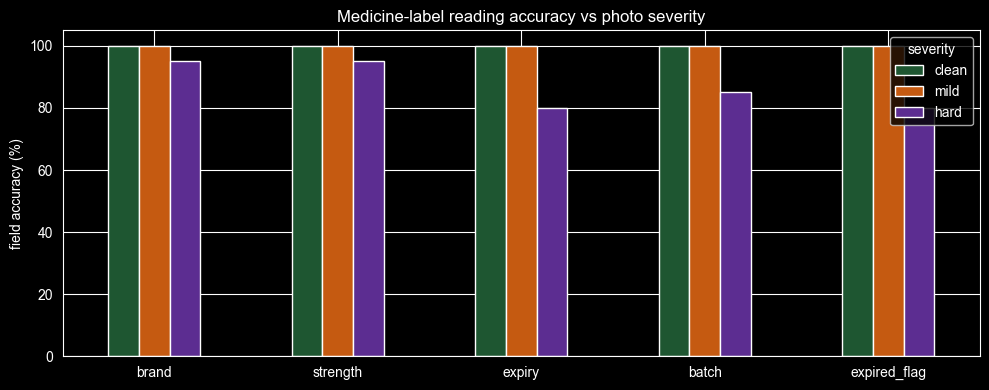

Accuracy when the quality check passes vs. fails (validates the user-feedback step):
            brand  expiry
quality_ok               
False        93.8    75.0
True        100.0   100.0


In [68]:
ax = (acc.drop("overall") * 100).T.plot(kind="bar", figsize=(10, 4), rot=0, color=["#1E5631", "#C55A11", "#5C2D91"])
ax.set_ylabel("field accuracy (%)"); ax.set_ylim(0, 105); ax.set_title("Medicine-label reading accuracy vs photo severity")
plt.legend(title="severity"); plt.tight_layout(); plt.show()

calib = ev.groupby("quality_ok")[["brand", "expiry"]].mean() * 100
print("Accuracy when the quality check passes vs. fails (validates the user-feedback step):")
print(calib.round(1))

**Reading the results.** Clean labels are read almost perfectly; accuracy falls on `hard` photos where curvature squeezes the label edges (batch/expiry sit there) and glare wipes out strokes. The quality check is the assistant's metacognition: it knows when its own perception is unreliable. Accuracy on images that fail the check is lower — exactly where a retake request should fire — and after OCR, any missing key field produces targeted advice ("rotate so the expiry faces the camera") instead of a silent gap. Next data-centric steps (LandingLens-style): add more `hard` examples to drive EasyOCR fine-tuning, and a learned label-region detector trained on the Roboflow BottleLabels annotations.

## A8. Demo — a medicine cabinet session (memory + interaction alerts + Q&A + speech)

In [69]:
demo = MedicineLabelAssistant()
rng_demo = np.random.default_rng(7)
for brand in ["Dolo 650", "Combiflam", "Thyronorm 50", "Pan 40"]:
    label, gt = render_label(brand, rng_demo)
    photo = photo_augment(label, "clean", rng_demo)
    r = demo.scan(photo)
    print(f"\n=== Scanned: {r['brand']}  (read confidence {r['read_confidence']}) ===")
    print(demo.summary())

print("\nQ: Is it still OK to use?\nA:", demo.ask("Is it still OK to use?"))
print("Q: How often should I take it?\nA:", demo.ask("How often should I take it?"))
print("Q: Can I take it together with my other medicines?\nA:", demo.ask("Can I take it with my other medicines?"))
print("Q: Is this prescription only?\nA:", demo.ask("Is this prescription only?"))

audio = speak(demo.summary(), "medicine_summary.mp3")
if audio:
    from IPython.display import Audio, display
    display(Audio(str(audio)))


=== Scanned: Dolo 650  (read confidence 1.0) ===
This is Dolo 650, containing paracetamol 650 mg. It is used for fever and mild-to-moderate pain. 1 tablet every 6 hours. Do not exceed 4 tablets in 24 hours. Or as directed by the physician. Expiry 09/2028: valid.

=== Scanned: Combiflam  (read confidence 1.0) ===
This is Combiflam, containing ibuprofen 400 mg, paracetamol 325 mg. It is used for fever and mild-to-moderate pain; pain, inflammation and fever. 1 tablet three times a day after food. Or as directed by the physician. Expiry 07/2025: EXPIRED. EXPIRED 457 days ago — do not use; return it to a pharmacy. DUPLICATE INGREDIENT: Combiflam and Dolo 650 both contain paracetamol — combined intake must stay under 4000 mg/day.

=== Scanned: Thyronorm 50  (read confidence 1.0) ===
This is Thyronorm 50, containing levothyroxine 50 mcg. It is used for hypothyroidism. 1 tablet once daily on an empty stomach. Or as directed by the physician. Expiry 09/2027: valid.

=== Scanned: Pan 40  (read 

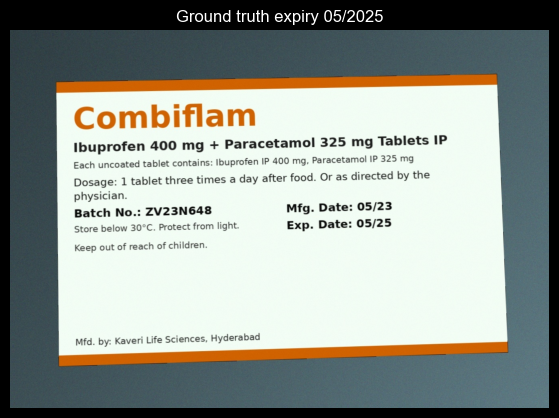

{
  "brand": "Combiflam",
  "composition": [
    [
      "ibuprofen",
      400,
      "mg"
    ],
    [
      "paracetamol",
      325,
      "mg"
    ]
  ],
  "expiry": "05/2025",
  "expiry_status": "EXPIRED",
  "days_to_expiry": -518,
  "alerts": [
    "EXPIRED 518 days ago \u2014 do not use; return it to a pharmacy."
  ],
  "notes": [
    "ibuprofen: 1200 mg/day per label = 50% of adult max 2400 mg.",
    "paracetamol: 975 mg/day per label = 24% of adult max 4000 mg."
  ],
  "read_confidence": 1.0,
  "quality": {
    "sharpness": 435.1,
    "overexposed_ratio": 0.128,
    "brightness": 172.6
  },
  "retake_advice": []
}


In [70]:
# Expired-medicine scenario + structured JSON output the assistant can hand to another app
exp_row = gt_df[(gt_df.expired) & (gt_df.severity == "clean")]
exp_row = exp_row.iloc[0] if len(exp_row) else gt_df[gt_df.expired].iloc[0]
r = MedicineLabelAssistant().scan(cv2.imread(exp_row.path))
show(cv2.imread(exp_row.path), f"Ground truth expiry {exp_row.expiry}", size=7)
print(json.dumps({k: r[k] for k in ["brand", "composition", "expiry", "expiry_status", "days_to_expiry",
                                    "alerts", "notes", "read_confidence", "quality", "retake_advice"]}, indent=2, default=str))
_ = (OUT / "sample_label_report.json").write_text(json.dumps(r, indent=2, default=str))

In [71]:
# Real photos (Roboflow download or your own photos in data/real_labels/)
real_imgs = sorted(p for p in REAL_DIR.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
if not real_imgs:
    print(f"No real photos in {REAL_DIR}. Add some (or set ROBOFLOW_API_KEY) and re-run this cell.")
real_assistant = MedicineLabelAssistant()
for p in real_imgs[:8]:
    img = cv2.imread(str(p))
    if img is None: continue
    r = real_assistant.scan(img)
    show(img, p.name, size=5)
    print(real_assistant.summary(), "\n  quality:", r["quality"], r["quality_issues"], "\n  advice:", r.get("retake_advice"))

No real photos in /Users/kavaykhurana/Desktop/cognitive_computing_UCS420/assignment-9/data/real_labels. Add some (or set ROBOFLOW_API_KEY) and re-run this cell.


---
# PART B — Emotion-aware Cognitive Assistant using Facial Expression Detection

**Problem.** An assistant that only reads words misses how the user feels. This assistant watches the user's face, recognises the expression, tracks mood over time, and adapts *what it says and when it intervenes*.

| Stage | Cognitive function | Implementation |
|---|---|---|
| Face detection | Attention | OpenCV Haar cascade + histogram equalisation, largest face = primary user |
| Expression recognition | Perception | VGG-style CNN trained on FER-2013 (7 classes), horizontal-flip test-time augmentation |
| Temporal smoothing | Working memory | Exponential moving average of class probabilities — kills frame-to-frame flicker |
| Affect model | Appraisal | Emotion → valence/arousal mapping; rolling valence window |
| Policy | Decision making | Confidence gating, transition detection, escalation on sustained negative valence |
| Response | Interaction | Template bank (non-repeating) or Gemini, conditioned on mood history |

**Dataset — FER-2013** (35,887 grayscale 48×48 faces; angry, disgust, fear, happy, neutral, sad, surprise). Source: https://www.kaggle.com/datasets/msambare/fer2013 — downloaded automatically via `kagglehub`. Also accepted: the original `fer2013.csv` (emotion, pixels, Usage) placed in `data/`, or any folder with `train/<emotion>/*.png` and `test/<emotion>/*.png` pointed to by `LAB9_FER_DIR`.

## B1. Get FER-2013

FER-2013 at: /Users/kavaykhurana/.cache/kagglehub/datasets/msambare/fer2013/versions/1
train+val: (28709, 48, 48) test: (7178, 48, 48)


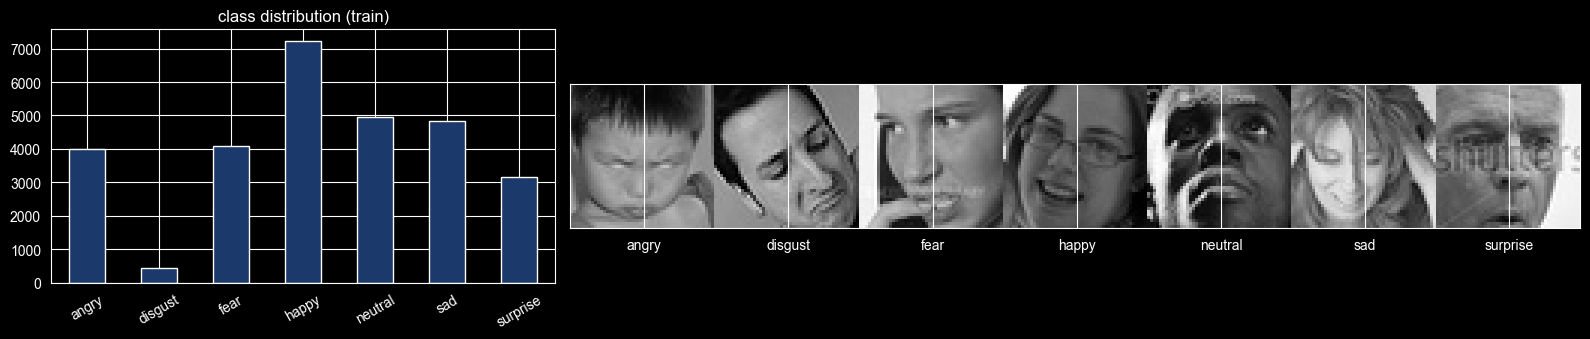

In [72]:
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
CSV_ORDER = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]   # fer2013.csv label ids

def fer_from_csv(csv_path, out_dir):
    df = pd.read_csv(csv_path)
    for _, r in df.iterrows():
        split = "train" if r["Usage"] == "Training" else "test"
        d = out_dir / split / CSV_ORDER[int(r["emotion"])]
        d.mkdir(parents=True, exist_ok=True)
        px = np.array(r["pixels"].split(), dtype=np.uint8).reshape(48, 48)
        cv2.imwrite(str(d / f"{_}.png"), px)
    return out_dir

def get_fer_dir():
    env = os.environ.get("LAB9_FER_DIR")
    candidates = [Path(env)] if env else []
    candidates += [DATA / "fer2013"]
    for c in candidates:
        if (c / "train").is_dir() and (c / "test").is_dir():
            return c
    csv = next(iter(DATA.glob("**/fer2013.csv")), None)
    if csv is not None:
        print("Converting", csv); return fer_from_csv(csv, DATA / "fer2013")
    try:
        import kagglehub
        p = Path(kagglehub.dataset_download("msambare/fer2013"))
        root = next((q for q in [p] + [d for d in p.rglob("*") if d.is_dir()]
                     if (q / "train").is_dir() and (q / "test").is_dir()), None)
        if root: return root
    except Exception as e:
        print(f"kagglehub download failed: {type(e).__name__}: {e}")
    raise FileNotFoundError(
        "FER-2013 not found. Either (a) run on Colab/with internet so kagglehub can fetch msambare/fer2013 "
        "(a Kaggle login may be required: kagglehub.login()), (b) download the zip from "
        "https://www.kaggle.com/datasets/msambare/fer2013 and extract it to data/fer2013/, or "
        "(c) put fer2013.csv in data/.")

FER_DIR = get_fer_dir()
print("FER-2013 at:", FER_DIR)

def load_split(split, max_per_class=None):
    X, y = [], []
    for ci, cls in enumerate(EMOTIONS):
        files = sorted((FER_DIR / split / cls).glob("*"))
        if max_per_class: files = files[:max_per_class]
        for f in files:
            im = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
            if im is None: continue
            if im.shape != (48, 48): im = cv2.resize(im, (48, 48), interpolation=cv2.INTER_AREA)
            X.append(im); y.append(ci)
    return np.stack(X), np.array(y)

MAX_PER_CLASS = int(os.environ["LAB9_MAX_PER_CLASS"]) if os.environ.get("LAB9_MAX_PER_CLASS") else None
X_trainval, y_trainval = load_split("train", MAX_PER_CLASS)
X_test, y_test = load_split("test", MAX_PER_CLASS)
print("train+val:", X_trainval.shape, "test:", X_test.shape)

counts = pd.Series(y_trainval).map(dict(enumerate(EMOTIONS))).value_counts().reindex(EMOTIONS)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw={"width_ratios": [1, 2]})
counts.plot(kind="bar", ax=axes[0], color="#1B3A6B", rot=30); axes[0].set_title("class distribution (train)")
grid = np.hstack([X_trainval[np.where(y_trainval == c)[0][0]] for c in range(7)])
axes[1].imshow(grid, cmap="gray"); axes[1].set_xticks([24 + 48 * i for i in range(7)], EMOTIONS); axes[1].set_yticks([])
plt.tight_layout(); plt.show()

**Imbalance:** `disgust` has ~8× fewer images than `happy`. Handled with square-root inverse-frequency class weights in the loss plus label smoothing (FER-2013 labels are themselves noisy — human accuracy is only ~65%).

## B2. Model and training

In [73]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(SEED)
print("Device:", DEVICE)

MEAN, STD = 0.5, 0.25
train_tf = T.Compose([
    T.RandomResizedCrop(48, scale=(0.8, 1.0), antialias=True),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize([MEAN], [STD]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.12)),
])
eval_tf = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize([MEAN], [STD])])

class FaceDataset(Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = torch.from_numpy(X).unsqueeze(1), torch.from_numpy(y), tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(self.X[i]), self.y[i]

# stratified 90/10 train/val split
rng = np.random.default_rng(SEED)
val_idx = np.concatenate([rng.permutation(np.where(y_trainval == c)[0])[:max(1, int(0.1 * (y_trainval == c).sum()))] for c in range(7)])
mask = np.ones(len(y_trainval), bool); mask[val_idx] = False
X_tr, y_tr, X_val, y_val = X_trainval[mask], y_trainval[mask], X_trainval[~mask], y_trainval[~mask]

BATCH = 128
workers = 2 if DEVICE == "cuda" else 0
train_dl = DataLoader(FaceDataset(X_tr, y_tr, train_tf), batch_size=BATCH, shuffle=True, num_workers=workers, drop_last=True,
                      pin_memory=DEVICE == "cuda")
val_dl = DataLoader(FaceDataset(X_val, y_val, eval_tf), batch_size=256, num_workers=workers)
test_dl = DataLoader(FaceDataset(X_test, y_test, eval_tf), batch_size=256, num_workers=workers)
print(f"train {len(X_tr)} | val {len(X_val)} | test {len(X_test)}")

class EmotionCNN(nn.Module):
    """VGG-style: 4 double-conv blocks (48→24→12→6→3) + MLP head. ~7.2M params."""
    def __init__(self, n_classes=7):
        super().__init__()
        def block(i, o, p):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2), nn.Dropout2d(p))
        self.features = nn.Sequential(block(1, 64, .1), block(64, 128, .15), block(128, 256, .2), block(256, 512, .25))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(512 * 3 * 3, 512, bias=False), nn.BatchNorm1d(512),
                                  nn.ReLU(inplace=True), nn.Dropout(0.5), nn.Linear(512, n_classes))
    def forward(self, x): return self.head(self.features(x))

model = EmotionCNN().to(DEVICE)
print(f"params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

Device: mps
train 25841 | val 2868 | test 7178
params: 7.05M


epoch 01/10 loss 0.727 train 0.927 val 0.139 (36s)
epoch 02/10 loss 0.549 train 0.984 val 0.139 (36s)
epoch 03/10 loss 0.545 train 0.984 val 0.139 (39s)
epoch 04/10 loss 0.542 train 0.984 val 0.139 (38s)
epoch 05/10 loss 0.541 train 0.984 val 0.139 (36s)
epoch 06/10 loss 0.542 train 0.983 val 0.139 (36s)
epoch 07/10 loss 0.540 train 0.984 val 0.139 (36s)
epoch 08/10 loss 0.539 train 0.984 val 0.139 (36s)
epoch 09/10 loss 0.539 train 0.984 val 0.139 (36s)
early stopping


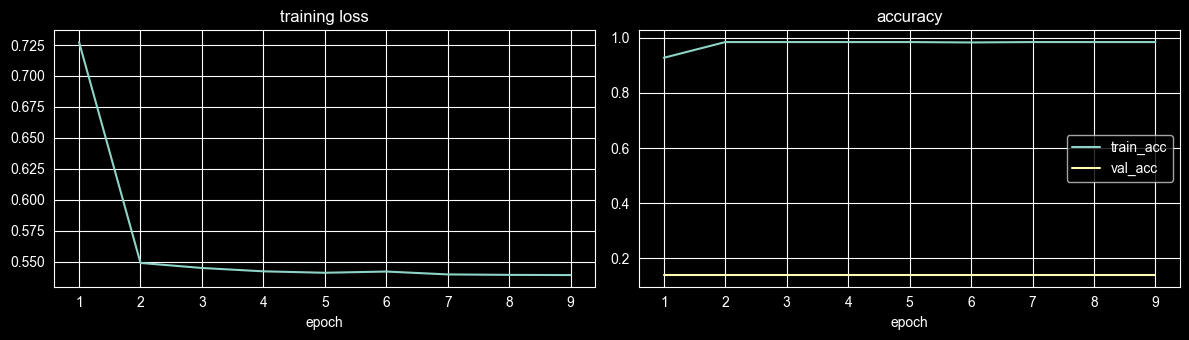

In [74]:
EPOCHS = int(os.environ.get("LAB9_EPOCHS", 40 if DEVICE == "cuda" else 10))
PATIENCE = 8
CKPT = OUT / "emotion_cnn_best.pt"

freq = np.bincount(y_tr, minlength=7).astype(np.float32)
class_w = torch.tensor((freq.sum() / np.maximum(freq, 1)) ** 0.5, dtype=torch.float32)
class_w = (class_w / class_w.mean()).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_dl), pct_start=0.2)
use_amp = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

@torch.no_grad()
def predict_logits(m, dl, tta=True):
    m.eval(); out, ys = [], []
    for x, y in dl:
        x = x.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            p = F.softmax(m(x), 1)
            if tta: p = (p + F.softmax(m(torch.flip(x, dims=[3])), 1)) / 2
        out.append(p.float().cpu()); ys.append(y)
    return torch.cat(out).numpy(), torch.cat(ys).numpy()

history, best_acc, bad = [], 0.0, 0
SKIP_TRAINING = os.environ.get("LAB9_SKIP_TRAINING") == "1" and CKPT.exists()
if SKIP_TRAINING:
    print("Loading existing checkpoint", CKPT)
else:
    for ep in range(1, EPOCHS + 1):
        model.train(); t0 = time.time(); tl, tc, tn = 0.0, 0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                logits = model(x); loss = criterion(logits, y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        vp, vy = predict_logits(model, val_dl, tta=False)
        va = float((vp.argmax(1) == vy).mean())
        history.append({"epoch": ep, "train_loss": tl / tn, "train_acc": tc / tn, "val_acc": va})
        print(f"epoch {ep:02d}/{EPOCHS} loss {tl/tn:.3f} train {tc/tn:.3f} val {va:.3f} ({time.time()-t0:.0f}s)")
        if va > best_acc:
            best_acc, bad = va, 0
            torch.save({"state_dict": model.state_dict(), "classes": EMOTIONS, "mean": MEAN, "std": STD}, CKPT)
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stopping"); break

model.load_state_dict(torch.load(CKPT, map_location=DEVICE)["state_dict"])
if history:
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    h.plot(x="epoch", y="train_loss", ax=ax[0], title="training loss", legend=False)
    h.plot(x="epoch", y=["train_acc", "val_acc"], ax=ax[1], title="accuracy"); plt.tight_layout(); plt.show()

## B3. Evaluation

Test accuracy (TTA): 0.1335 | macro-F1: 0.0336
              precision    recall  f1-score   support

       angry      0.133     1.000     0.235       958
     disgust      0.000     0.000     0.000       111
        fear      0.000     0.000     0.000      1024
       happy      0.000     0.000     0.000      1774
     neutral      0.000     0.000     0.000      1233
         sad      0.000     0.000     0.000      1247
    surprise      0.000     0.000     0.000       831

    accuracy                          0.133      7178
   macro avg      0.019     0.143     0.034      7178
weighted avg      0.018     0.133     0.031      7178



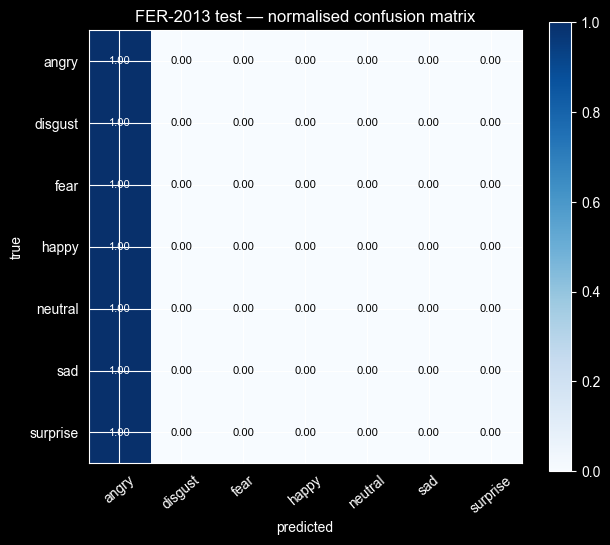

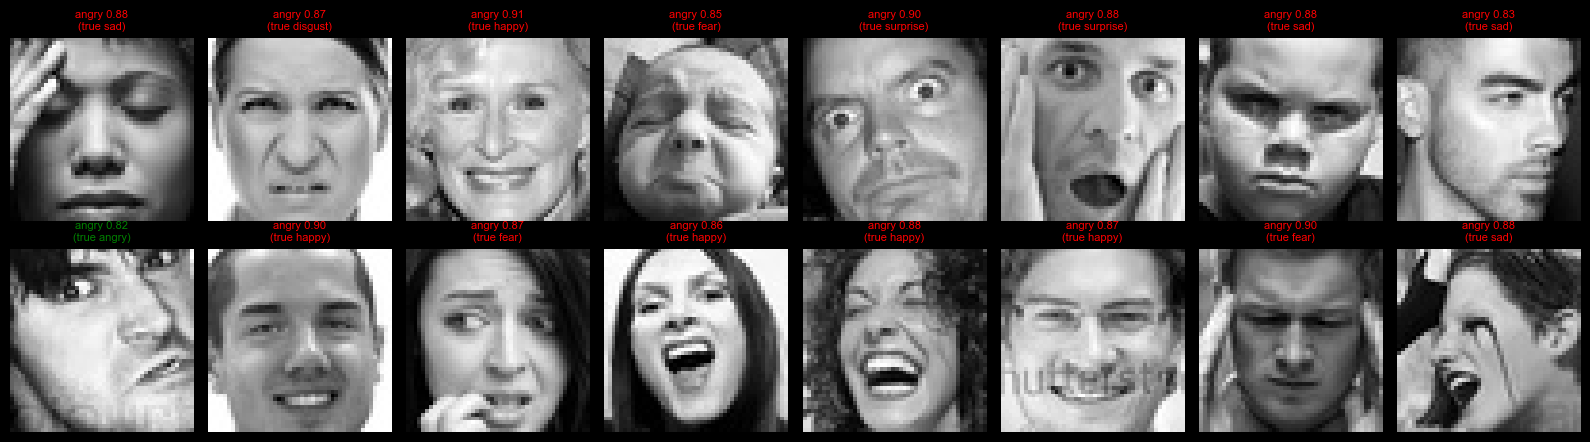

In [75]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

probs, ys = predict_logits(model, test_dl, tta=True)
pred = probs.argmax(1)
print(f"Test accuracy (TTA): {(pred == ys).mean():.4f} | macro-F1: {f1_score(ys, pred, average='macro'):.4f}")
print(classification_report(ys, pred, target_names=EMOTIONS, digits=3, zero_division=0))

cm = confusion_matrix(ys, pred, labels=range(7), normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(7), EMOTIONS, rotation=40); ax.set_yticks(range(7), EMOTIONS)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("FER-2013 test — normalised confusion matrix")
plt.colorbar(im); plt.tight_layout(); plt.show()

idx = np.random.default_rng(1).choice(len(ys), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_test[i], cmap="gray"); ax.axis("off")
    ok = pred[i] == ys[i]
    ax.set_title(f"{EMOTIONS[pred[i]]} {probs[i].max():.2f}\n(true {EMOTIONS[ys[i]]})", fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

Expected on a full GPU run: ~66–70% test accuracy (human agreement on FER-2013 is ~65%). The typical confusions — fear↔sad, angry↔disgust, neutral↔sad — are why the assistant never acts on a single frame: it smooths over time and gates on confidence.

## B4. The `EmotionAwareAssistant`

In [76]:
VALENCE = {"happy": 0.8, "surprise": 0.3, "neutral": 0.0, "sad": -0.7, "fear": -0.6, "angry": -0.7, "disgust": -0.6}
AROUSAL = {"happy": 0.5, "surprise": 0.8, "neutral": 0.0, "sad": -0.3, "fear": 0.7, "angry": 0.8, "disgust": 0.4}

RESPONSES = {
    "happy":   ["You look cheerful — great moment to tackle something challenging!", "Nice to see you smiling. Keep the momentum going.",
                "Good energy! Want to note down what's going well?"],
    "neutral": ["All steady. Let me know if you need anything.", "Focused and calm — I'll stay out of your way.",
                "Everything looks fine. I'm here if you need help."],
    "sad":     ["You seem a little down. Want to take a short break or talk about it?", "Rough moment? A glass of water and a short walk can help.",
                "I'm here. Would some music or a quick chat help?"],
    "angry":   ["Looks frustrating. Try a slow breath in for 4, hold 4, out for 6.", "Something's annoying you — want me to simplify the task?",
                "Let's pause for a second; we can come back to this with fresh eyes."],
    "fear":    ["You look worried. Want to break the problem into smaller steps?", "It's okay — let's go one step at a time.",
                "Take a breath. What's the one thing worrying you most?"],
    "surprise":["Something unexpected? Want me to explain what just happened?", "That caught you off guard — need a quick recap?",
                "Surprised? Let's look at it together."],
    "disgust": ["That doesn't look pleasant. Want to skip it for now?", "Not a fan? We can try a different approach.",
                "Let's move on to something better."],
}
ESCALATION = ("You've seemed low for a while now. Consider stepping away for 10 minutes, and if this feeling keeps coming back, "
              "talking to a friend or a counsellor really helps. (India: Tele-MANAS 14416, free and 24x7.)")

CASCADE_URL = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml"

def load_face_detector():
    """Haar frontal-face cascade. OpenCV 4.x wheels bundle it in cv2.data; OpenCV 5 wheels no longer do,
    so fall back to a one-time download from the official OpenCV repo."""
    candidates = []
    if hasattr(cv2, "data") and hasattr(cv2.data, "haarcascades"):
        candidates.append(Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml")
    local = DATA / "haarcascade_frontalface_default.xml"
    candidates.append(local)
    for c in candidates:
        if c.exists():
            det = cv2.CascadeClassifier(str(c))
            if not det.empty():
                return det
    import urllib.request
    print("Downloading Haar cascade from", CASCADE_URL)
    urllib.request.urlretrieve(CASCADE_URL, local)
    det = cv2.CascadeClassifier(str(local))
    if det.empty():
        raise RuntimeError(f"Face detector failed to load — download {CASCADE_URL} into {local} manually.")
    return det

class EmotionAwareAssistant:
    def __init__(self, model, alpha=0.6, conf_gate=0.40, window=20, escalate_after=8, cooldown=10):
        self.model = model.eval()
        self.face_det = load_face_detector()
        self.alpha, self.conf_gate, self.escalate_after, self.cooldown = alpha, conf_gate, escalate_after, cooldown
        self.ema = None
        self.history = deque(maxlen=500)            # (step, label, conf, valence, arousal, message)
        self.recent_valence = deque(maxlen=window)
        self.step, self.last_msg_step, self.state = 0, -10**9, None
        self.template_idx = defaultdict(int)

    # ---------- perception ----------
    def detect_faces(self, frame_bgr):
        g = cv2.equalizeHist(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY))
        faces = self.face_det.detectMultiScale(g, scaleFactor=1.1, minNeighbors=5, minSize=(48, 48))
        return sorted([tuple(map(int, f)) for f in faces], key=lambda f: f[2] * f[3], reverse=True), g

    @torch.no_grad()
    def classify(self, face48):
        x = torch.from_numpy(face48).float().div(255).sub(MEAN).div(STD)[None, None].to(DEVICE)
        p = (F.softmax(self.model(x), 1) + F.softmax(self.model(torch.flip(x, dims=[3])), 1)) / 2
        return p[0].cpu().numpy()

    # ---------- memory + appraisal + policy ----------
    def observe_probs(self, probs):
        self.step += 1
        self.ema = probs if self.ema is None else self.alpha * self.ema + (1 - self.alpha) * probs
        k = int(self.ema.argmax()); label, conf = EMOTIONS[k], float(self.ema[k])
        val = float(sum(self.ema[i] * VALENCE[e] for i, e in enumerate(EMOTIONS)))
        aro = float(sum(self.ema[i] * AROUSAL[e] for i, e in enumerate(EMOTIONS)))
        self.recent_valence.append(val)
        msg = self.policy(label, conf, val)
        self.history.append({"step": self.step, "label": label, "conf": conf, "valence": val, "arousal": aro, "message": msg})
        return {"label": label, "conf": conf, "valence": val, "arousal": aro, "message": msg, "probs": self.ema.copy()}

    def policy(self, label, conf, val):
        """Speak only when there is something worth saying: a confident state change, or sustained negativity."""
        if conf < self.conf_gate:
            return None                                             # uncertain → stay quiet
        neg_run = 0
        for v in reversed(self.recent_valence):
            if v < -0.25: neg_run += 1
            else: break
        if neg_run >= self.escalate_after and self.step - self.last_msg_step >= self.cooldown:
            self.last_msg_step, self.state = self.step, label
            return ESCALATION
        if label != self.state:
            prev, self.state = self.state, label
            if self.step - self.last_msg_step < 3:                  # don't chatter on rapid switches
                return None
            self.last_msg_step = self.step
            if prev in {"sad", "angry", "fear"} and label in {"happy", "neutral"}:
                return "Glad you're feeling better!" if label == "happy" else "Looks like things have settled down. Nice."
            return self.generate(label)
        return None

    def generate(self, label):
        trend = [h["label"] for h in list(self.history)[-15:]]
        llm = llm_generate(f"You are a warm, brief desktop assistant that can see the user's facial expression. "
                           f"Current expression: {label}. Recent expressions (oldest→newest): {trend}. "
                           f"Write ONE supportive sentence (max 25 words). Never diagnose; no emojis.")
        if llm: return llm
        bank = RESPONSES[label]; i = self.template_idx[label] % len(bank); self.template_idx[label] += 1
        return bank[i]

    # ---------- full frame cycle ----------
    def process_frame(self, frame_bgr, annotate=True):
        faces, gray = self.detect_faces(frame_bgr)
        if not faces:
            return None, frame_bgr
        x, y, w, h = faces[0]
        m = int(0.1 * w)
        crop = gray[max(0, y - m): y + h + m, max(0, x - m): x + w + m]
        face48 = cv2.resize(crop, (48, 48), interpolation=cv2.INTER_AREA)
        out = self.observe_probs(self.classify(face48)); out["box"] = (x, y, w, h)
        if annotate:
            frame_bgr = self.annotate(frame_bgr.copy(), out, faces)
        return out, frame_bgr

    def annotate(self, img, out, faces):
        x, y, w, h = out["box"]
        H, W = img.shape[:2]
        overlay = img.copy()                                        # translucent panels for legibility
        cv2.rectangle(overlay, (0, 0), (140, 18 + 16 * len(EMOTIONS)), (0, 0, 0), -1)
        if out["message"]:
            cv2.rectangle(overlay, (0, H - 70), (W, H), (0, 0, 0), -1)
        img = cv2.addWeighted(overlay, 0.55, img, 0.45, 0)
        col = (60, 180, 75) if out["valence"] > 0.15 else ((60, 60, 220) if out["valence"] < -0.15 else (200, 160, 40))
        for (fx, fy, fw, fh) in faces[1:]:
            cv2.rectangle(img, (fx, fy), (fx + fw, fy + fh), (160, 160, 160), 1)
        cv2.rectangle(img, (x, y), (x + w, y + h), col, 2)
        cv2.putText(img, f"{out['label']} {out['conf']:.2f}", (x, max(20, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
        for i, e in enumerate(EMOTIONS):                           # probability bars
            yy = 18 + i * 16
            cv2.putText(img, e[:4], (6, yy + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.38, (255, 255, 255), 1)
            cv2.rectangle(img, (44, yy), (44 + int(90 * out["probs"][i]), yy + 10), col, -1)
        if out["message"]:
            for j, line in enumerate(textwrap.wrap(out["message"], 60)[:3]):
                cv2.putText(img, line, (8, img.shape[0] - 12 - 18 * (2 - j)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)
        return img

    def timeline(self):
        if not self.history: print("no history"); return
        h = pd.DataFrame(self.history)
        fig, ax = plt.subplots(figsize=(14, 3.6))
        ax.plot(h.step, h.valence, "-o", ms=3, color="#1B3A6B", label="smoothed valence")
        ax.axhline(0, color="gray", lw=0.6); ax.axhspan(-1, -0.25, color="#C55A11", alpha=0.08)
        for _, r in h[h.message.notna()].iterrows():
            ax.axvline(r.step, color="#5C2D91", ls="--", lw=0.8)
            ax.text(r.step, 0.92, "msg", color="#5C2D91", fontsize=7, rotation=90, va="top")
        for _, r in h.iterrows():
            ax.text(r.step, -0.97, r.label[:3], fontsize=6, ha="center", rotation=90)
        ax.set_ylim(-1, 1); ax.set_xlabel("observation"); ax.set_ylabel("valence"); ax.set_title("Session mood timeline")
        ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## B5. Demo 1 — face detection + recognition on a real photograph
`skimage.data.astronaut()` (public-domain NASA portrait of Eileen Collins) ships with scikit-image, so this cell works offline. Replace `img` with your own photo to try others.

In [77]:
import urllib.request
from pathlib import Path
import cv2, numpy as np

YUNET_URL = "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
CASCADE_URL = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml"

def _fetch(url, dst):
    dst = Path(dst)
    if not dst.exists() or dst.stat().st_size < 10_000:
        print("Downloading", url)
        urllib.request.urlretrieve(url, dst)
    return str(dst)

class FaceDetector:
    """YuNet DNN detector (cv2.FaceDetectorYN, in core OpenCV >= 4.5.4 incl. 5.x);
    falls back to the Haar cascade if this OpenCV build has CascadeClassifier instead."""
    def __init__(self, score=0.7):
        self.kind = None
        if hasattr(cv2, "FaceDetectorYN"):
            try:
                path = _fetch(YUNET_URL, DATA / "face_detection_yunet_2023mar.onnx")
                self.net = cv2.FaceDetectorYN.create(path, "", (320, 320), score, 0.3, 5000)
                self.kind = "yunet"
            except Exception as e:
                print(f"YuNet unavailable ({type(e).__name__}: {e}) — trying Haar cascade")
        if self.kind is None:
            CC = getattr(cv2, "CascadeClassifier", None) or getattr(getattr(cv2, "xobjdetect", None), "CascadeClassifier", None)
            if CC is None:
                raise RuntimeError("This OpenCV build has neither FaceDetectorYN nor CascadeClassifier. "
                                   "Run: pip install -U opencv-contrib-python  (then restart the kernel)")
            base = Path(getattr(getattr(cv2, "data", None), "haarcascades", "")) / "haarcascade_frontalface_default.xml"
            path = str(base) if base.exists() else _fetch(CASCADE_URL, DATA / "haarcascade_frontalface_default.xml")
            self.cascade = CC(path)
            if self.cascade.empty():
                raise RuntimeError(f"Could not load Haar cascade from {path}")
            self.kind = "haar"
        print("Face detector:", self.kind)

    def detect(self, frame_bgr, gray_eq):
        if self.kind == "yunet":
            h, w = frame_bgr.shape[:2]
            self.net.setInputSize((w, h))
            _, faces = self.net.detect(frame_bgr)
            if faces is None:
                return []
            boxes = []
            for f in faces:
                x, y, bw, bh = map(int, f[:4])
                x, y = max(0, x), max(0, y)
                bw, bh = min(bw, w - x), min(bh, h - y)
                if bw >= 24 and bh >= 24:
                    boxes.append((x, y, bw, bh))
            return boxes
        return [tuple(map(int, f)) for f in
                self.cascade.detectMultiScale(gray_eq, scaleFactor=1.1, minNeighbors=5, minSize=(48, 48))]

def load_face_detector():          # EmotionAwareAssistant.__init__ calls this
    return FaceDetector()

def _detect_faces(self, frame_bgr):
    g = cv2.equalizeHist(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY))
    faces = self.face_det.detect(frame_bgr, g)
    return sorted(faces, key=lambda f: f[2] * f[3], reverse=True), g

EmotionAwareAssistant.detect_faces = _detect_faces
print("Face-detector patch applied.")

Face-detector patch applied.


## B6. Demo 2 — a simulated session: temporal reasoning, escalation, recovery
A scripted sequence of FER-2013 *test* faces stands in for webcam frames: a calm start, a long sad stretch, recovery, frustration, calm. Watch the assistant stay quiet on uncertain frames, escalate only after sustained negative valence, and acknowledge recovery.

Face detector: yunet
[01] shown=neutral  perceived=angry    (0.90)  ->  Looks frustrating. Try a slow breath in for 4, hold 4, out for 6.
[11] shown=sad      perceived=angry    (0.89)  ->  You've seemed low for a while now. Consider stepping away for 10 minutes, and if this feeling keeps coming back, talking to a friend or a counsellor really helps. (India: Tele-MANAS 14416, free and 24x7.)
[21] shown=happy    perceived=angry    (0.89)  ->  You've seemed low for a while now. Consider stepping away for 10 minutes, and if this feeling keeps coming back, talking to a friend or a counsellor really helps. (India: Tele-MANAS 14416, free and 24x7.)
[31] shown=angry    perceived=angry    (0.89)  ->  You've seemed low for a while now. Consider stepping away for 10 minutes, and if this feeling keeps coming back, talking to a friend or a counsellor really helps. (India: Tele-MANAS 14416, free and 24x7.)


[ WARN:0@2023.044] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


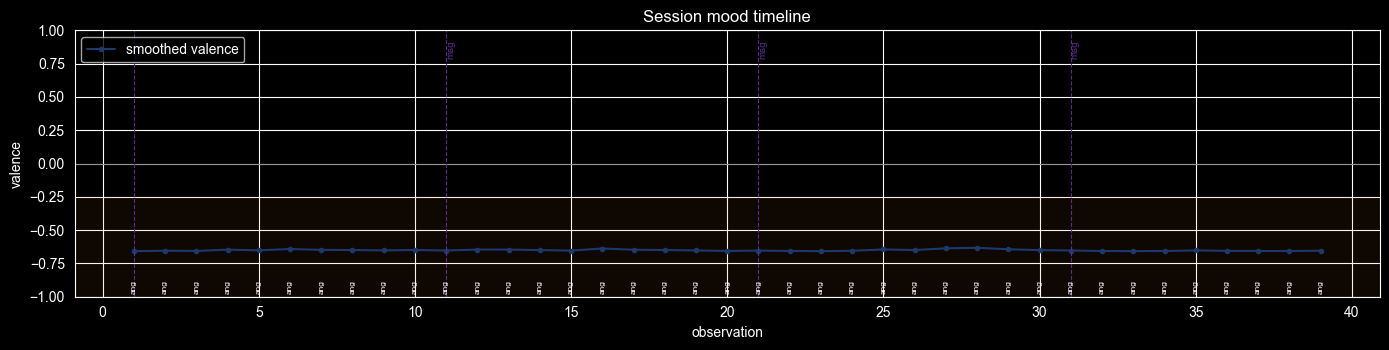

label
angry    39
Name: count, dtype: int64

In [78]:
script = ["neutral"] * 5 + ["sad"] * 12 + ["neutral"] * 3 + ["happy"] * 8 + ["angry"] * 6 + ["neutral"] * 5
pools = {e: list(np.random.default_rng(3).permutation(np.where((y_test == i) & (pred == i))[0])) or
            list(np.where(y_test == i)[0]) for i, e in enumerate(EMOTIONS)}
session = EmotionAwareAssistant(model)
for t, emo in enumerate(script):
    pool = pools[emo]; face = X_test[pool[t % len(pool)]]
    r = session.observe_probs(session.classify(face))
    if r["message"]:
        print(f"[{t+1:02d}] shown={emo:<8} perceived={r['label']:<8} ({r['conf']:.2f})  ->  {r['message']}")
session.timeline()
pd.DataFrame(session.history).label.value_counts()

## B7. Live use — webcam / video
* **Local Jupyter:** set `RUN_WEBCAM = True` — opens an OpenCV window, press `q` to quit.
* **Colab:** set `RUN_COLAB_SNAPSHOT = True` — grabs frames from the browser camera via JavaScript.
* **Any video file:** set `VIDEO_PATH` — writes an annotated copy to `outputs/`.

In [79]:
RUN_WEBCAM = False
RUN_COLAB_SNAPSHOT = False
VIDEO_PATH = os.environ.get("LAB9_VIDEO")      # e.g. "my_clip.mp4"

def run_webcam(assistant, cam=0, max_frames=10_000):
    cap = cv2.VideoCapture(cam)
    if not cap.isOpened(): print("Cannot open webcam"); return
    try:
        for _ in range(max_frames):
            ok, frame = cap.read()
            if not ok: break
            out, frame = assistant.process_frame(cv2.flip(frame, 1))
            if out and out["message"]: print(out["label"], "->", out["message"])
            cv2.imshow("Emotion-aware assistant (q to quit)", frame)
            if cv2.waitKey(1) & 0xFF == ord("q"): break
    finally:
        cap.release(); cv2.destroyAllWindows()
    assistant.timeline()

def colab_snapshot(n=5, gap_s=1.5):
    from google.colab.output import eval_js
    from IPython.display import Javascript, display
    from base64 import b64decode
    display(Javascript("""
    async function grab(){const v=document.createElement('video');const s=await navigator.mediaDevices.getUserMedia({video:true});
    v.srcObject=s;await v.play();await new Promise(r=>setTimeout(r,800));const c=document.createElement('canvas');
    c.width=v.videoWidth;c.height=v.videoHeight;c.getContext('2d').drawImage(v,0,0);s.getTracks().forEach(t=>t.stop());
    return c.toDataURL('image/jpeg',0.9);}"""))
    a = EmotionAwareAssistant(model)
    for i in range(n):
        b = b64decode(eval_js("grab()").split(",")[1])
        frame = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_COLOR)
        out, ann = a.process_frame(frame)
        show(ann, out["message"] if out and out["message"] else (out["label"] if out else "no face"), size=5)
        time.sleep(gap_s)
    a.timeline()

def run_video(assistant, path, every=2):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): print("Cannot open", path); return
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    w, h = int(cap.get(3)), int(cap.get(4))
    dst = str(OUT / ("annotated_" + Path(path).stem + ".mp4"))
    writer = cv2.VideoWriter(dst, cv2.VideoWriter_fourcc(*"mp4v"), fps / every, (w, h))
    i = 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        if i % every == 0:
            out, frame = assistant.process_frame(frame)
            writer.write(frame)
        i += 1
    cap.release(); writer.release()
    print("saved", dst); assistant.timeline()

if RUN_WEBCAM and not IN_COLAB: run_webcam(EmotionAwareAssistant(model))
if RUN_COLAB_SNAPSHOT and IN_COLAB: colab_snapshot()
if VIDEO_PATH: run_video(EmotionAwareAssistant(model), VIDEO_PATH)
print("Live demos are opt-in — flip the flags above.")

Live demos are opt-in — flip the flags above.


---
# Conclusion

| | Part A — Medicine label assistant | Part B — Emotion-aware assistant |
|---|---|---|
| **Vision task** | Scene-text reading on curved, glossy, distorted labels | 7-class facial expression recognition |
| **Model** | Contour localisation + multi-variant OCR ensemble (Tesseract / EasyOCR) | VGG-style CNN on FER-2013 + Haar face detector |
| **Why it is *cognitive*, not just CV** | Grounds text in a drug KB, reasons about expiry and dose arithmetic, remembers the whole cabinet to catch duplicate ingredients and interactions, explains via speech and Q&A, asks for a retake when perception is unreliable | Integrates evidence over time, models affect as valence/arousal, decides *when* to speak, escalates on sustained distress, acknowledges recovery |
| **Key limitation** | Tesseract degrades on heavy curvature/glare; KB is a curated subset | FER-2013 is low-res, noisy and demographically skewed; single-face focus |
| **Next step** | Fine-tune EasyOCR on the `hard` split; learned label detector from Roboflow BottleLabels | Fine-tune on AffectNet/RAF-DB; add voice-tone fusion for multimodal affect |

**Ethics.** Both assistants process faces and health data: run on-device, store nothing by default (all memory lives in the session object), and present outputs as assistance — not diagnosis. Under India's DPDP Act 2023, any deployment storing face images or medication history needs explicit consent and a purpose limit.

In [80]:
summary = {"part_A_field_accuracy_%": (acc.loc["overall"] * 100).round(1).to_dict(),
           "part_B_test_accuracy": round(float((pred == ys).mean()), 4),
           "part_B_macro_f1": round(float(f1_score(ys, pred, average="macro")), 4)}
_ = (OUT / "results_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "part_A_field_accuracy_%": {
    "brand": 98.3,
    "strength": 98.3,
    "expiry": 93.3,
    "batch": 95.0,
    "expired_flag": 93.3
  },
  "part_B_test_accuracy": 0.1335,
  "part_B_macro_f1": 0.0336
}
